In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, LogNorm, Normalize
import seaborn as sns
import numpy as np
from collections import defaultdict

In [11]:
ROOT = Path().cwd()
DATA_INITIAL = Path("../data_initial").resolve()
DATA = Path("../data").resolve()
FANTOM = DATA / "fantom_cat"
FANTOM_INITIAL = DATA_INITIAL / "fantom_cat"
PREPROCESSING = Path("../preprocessing")

MATRICES = PREPROCESSING / "matrices"
IPS_MATRICES = MATRICES / "ips_matrices"
FIBRO_MATRICES = MATRICES / "fibro_matrices"

INFO = PREPROCESSING / "info"
IPS_INFO = INFO / "ips_info"
FIBRO_INFO = INFO / "fibro_info"

FISHER = PREPROCESSING / "fisher_test"
IPS_FISHER = FISHER / "ips_fisher_exact_test"
FIBRO_FISHER = FISHER / "fibro_fisher_exact_test"

RESULTS = Path("../results")
FISHER_RESULTS = RESULTS / "fisher_test"
JACCARD_RESULTS = RESULTS / "jaccard"
PERMUTATION_RES_AFTER_FDR = RESULTS / "rnachrom_himorna-intersection"

IMAGES = RESULTS / "images"

In [3]:
def heatmap_pval_blue_red(df, exp, save=False):
    from matplotlib.patches import Rectangle

    df["lnc_aso"] = df["lnc"] + "_" + df["aso"]
    cmap = ListedColormap(['blue', 'green', 'black', 'red'])
    bounds = [0, 0.01, 0.05, 0.1, 1]
    norm = BoundaryNorm(bounds, cmap.N)
    
    # Подготовка данных для тепловой карты
    df_for_heatmap = pd.pivot_table(
        data=df[["hm", "lnc_aso", "er", "ea", "wa", "wr"]], 
        index=["lnc_aso"], 
        columns="hm"
    ).sort_index(axis=1, level=1)
    
    # Создание фигуры и осей
    fig, ax = plt.subplots(figsize=(30, 20))
    
    # Добавление прозрачного желтого фона
    ax.add_patch(Rectangle(
        (0, 0),  # Нижний левый угол
        len(df_for_heatmap.columns),  # Ширина (по количеству столбцов)
        len(df_for_heatmap.index),   # Высота (по количеству строк)
        color='yellow',  # Цвет фона
        alpha=0.1,       # Прозрачность фона
        zorder=0         # Слой ниже всех элементов
    ))

    # Построение тепловой карты
    heatmap = sns.heatmap(
        df_for_heatmap, 
        cmap=cmap, 
        norm=norm, 
        annot=False, 
        linewidths=0.5,  # Толщина линий сетки
        linecolor='black',  # Цвет линий сетки
        cbar_kws={'boundaries': bounds, 'ticks': [0, 0.01, 0.05, 0.1, 1]},
        ax=ax
    )
    
    # Добавление порогового значения на легенду
    colorbar = heatmap.collections[0].colorbar
    colorbar.ax.axhline(0.05, color='yellow', linewidth=2)
    colorbar.ax.text(0.5, 0.05, '0.05', color='yellow', ha='center', va='center', transform=colorbar.ax.transAxes)
    
    # Настройка заголовка и сохранение
    plt.title(f'Heatmap with Custom Threshold Highlighted {exp}', fontsize=25)
    if save == True:
        plt.savefig(IMAGES / f"heatmap_pval_blue_red_{exp}.png")
    plt.show()

In [4]:
def heatmap_pval_blue_red_jaccard(df, exp):
    from matplotlib.patches import Rectangle

    df["lnc_aso"] = df["lnc"] + "_" + df["aso"]
    #df[['jaccard-er', 'jaccard-ea', 'jaccard-wa', 'jaccard-wr']] = df[['jaccard-er', 'jaccard-ea', 'jaccard-wa', 'jaccard-wr']]*100
    # Подготовка данных для тепловой карты
    df_for_heatmap = pd.pivot_table(
        data=df[["hm", "lnc_aso", 'jaccard-er', 'jaccard-ea', 'jaccard-wa', 'jaccard-wr']], 
        index=["lnc_aso"], 
        columns="hm"
    ).sort_index(axis=1, level=1)
    
    # Создание фигуры и осей
    fig, ax = plt.subplots(figsize=(30, 20))
    
    # Добавление прозрачного желтого фона
    ax.add_patch(Rectangle(
        (0, 0),  # Нижний левый угол
        len(df_for_heatmap.columns),  # Ширина (по количеству столбцов)
        len(df_for_heatmap.index),   # Высота (по количеству строк)
        color='yellow',  # Цвет фона
        alpha=0.1,       # Прозрачность фона
        zorder=0         # Слой ниже всех элементов
    ))

    # Построение тепловой карты
    heatmap = sns.heatmap(
        df_for_heatmap, 
        annot=False, 
        linewidths=0.5,  # Толщина линий сетки
        linecolor='black',  # Цвет линий сетки
        norm=LogNorm(),
        ax=ax
    )
    
    # Настройка заголовка и сохранение
    plt.title(f'Heatmap jaccard {exp}', fontsize=25)
    plt.savefig(IMAGES / f"heatmap_jaccard_blue_red_{exp}.png")
    plt.show()

In [5]:
jaccard_results_by_exp = {}
for exp in ["fibro", "ips"]:
    to_file = JACCARD_RESULTS / f"{exp}-jaccard-concat.tsv"
    jaccard_results = pd.read_csv(to_file, sep="\t")
    if exp == "fibro":
        jaccard_results["aso"] = jaccard_results["aso"].apply(lambda x: "_".join(x.split("_")[1:]))
    jaccard_results["lnc-hm"] = jaccard_results["lnc"] + "-" + jaccard_results["hm"]
    jaccard_results["lnc-aso-hm"] = jaccard_results["lnc"] + "-" + jaccard_results["aso"] + "-" + jaccard_results["hm"]
    jaccard_results_by_exp[exp] = jaccard_results    

In [21]:
fisher_results_filt_by_exp = {}
for exp in ["fibro", "ips"]:
    to_file = FISHER_RESULTS / f"{exp}-fisher-significant.tsv"
    fisher_results_filt = pd.read_csv(to_file, sep="\t")
    if exp == "fibro":
        fisher_results_filt["aso"] = fisher_results_filt["aso"].apply(lambda x: "_".join(x.split("_")[1:]))
    fisher_results_filt["lnc-hm"] = fisher_results_filt["lnc"] + "-" + fisher_results_filt["hm"]
    fisher_results_filt["lnc-aso-hm"] = fisher_results_filt["lnc"] + "-" + fisher_results_filt["aso"] + "-" + fisher_results_filt["hm"]
    fisher_results_filt_by_exp[exp] = fisher_results_filt    

In [6]:
fisher_results_filt_by_exp["fibro"]

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm
0,H3K9me3,ENSG00000163364,G0163364_AD_01,1.000000e+00,1.917683e-03,1.000000,1.000000,AC017048.3,AC017048.3-H3K9me3,AC017048.3-G0163364_AD_01-H3K9me3
1,H3K9me3,ENSG00000214548,G0214548_01,6.904775e-01,6.172479e-04,0.001780,0.696110,MEG3,MEG3-H3K9me3,MEG3-G0214548_01-H3K9me3
2,H3K9me3,ENSG00000214548,G0214548_AD_09,1.000000e+00,1.050761e-07,1.000000,0.000695,MEG3,MEG3-H3K9me3,MEG3-G0214548_AD_09-H3K9me3
3,H3K9me3,ENSG00000223478,G0223478_03,8.484336e-04,9.853195e-01,1.000000,1.000000,RP11-545E17.3,RP11-545E17.3-H3K9me3,RP11-545E17.3-G0223478_03-H3K9me3
4,H3K9me3,ENSG00000225470,G0225470_AD_04,1.000000e+00,1.000000e+00,0.002088,1.000000,JPX,JPX-H3K9me3,JPX-G0225470_AD_04-H3K9me3
...,...,...,...,...,...,...,...,...,...,...
277,H3K4me1,ENSG00000268895,G0268895_01,1.000000e+00,4.303351e-01,0.005312,1.000000,A1BG-AS1,A1BG-AS1-H3K4me1,A1BG-AS1-G0268895_01-H3K4me1
278,H3K4me1,ENSG00000268895,G0268895_03,7.864094e-04,4.142816e-01,0.000205,1.000000,A1BG-AS1,A1BG-AS1-H3K4me1,A1BG-AS1-G0268895_03-H3K4me1
279,H3K4me1,ENSG00000269834,G0269834_02,6.742146e-03,5.148661e-01,0.255875,1.000000,CTD-3018O17.3,CTD-3018O17.3-H3K4me1,CTD-3018O17.3-G0269834_02-H3K4me1
280,H3K4me1,ENSG00000269834,G0269834_AD_02,1.579246e-07,3.774202e-01,0.443793,1.000000,CTD-3018O17.3,CTD-3018O17.3-H3K4me1,CTD-3018O17.3-G0269834_AD_02-H3K4me1


In [7]:
jaccard_results_filt_by_exp = {}
for exp in ["fibro", "ips"]:
    mask = jaccard_results_by_exp[exp]["lnc-aso-hm"].isin(fisher_results_filt_by_exp[exp]["lnc-aso-hm"])
    print(mask.sum())
    jaccard_results_filt = jaccard_results_by_exp[exp][mask]
    jaccard_results_filt_by_exp[exp] = jaccard_results_filt

282
43


In [8]:
assert len(jaccard_results_filt_by_exp["ips"]) == len(fisher_results_filt_by_exp["ips"])
assert len(jaccard_results_filt_by_exp["fibro"]) == len(fisher_results_filt_by_exp["fibro"])

In [17]:
to_file = PERMUTATION_RES_AFTER_FDR / "bootstraped_paires"
bootstraped_paires = pd.read_csv(to_file, sep="\t")
bootstraped_paires.head(3)

,hm,lnc_x
0,H3K9me3,JPX
1,H3K9me3,RP11-395B7.4
2,H3K9me3,RP4-773A18.4


In [19]:
len(bootstraped_paires)

91

In [24]:
bootstraped_paires["lnc-hm"] = bootstraped_paires["lnc_x"] + "-" + bootstraped_paires["hm"]

In [25]:
bootstraped_paires

,hm,lnc_x,lnc-hm
0,H3K9me3,JPX,JPX-H3K9me3
1,H3K9me3,RP11-395B7.4,RP11-395B7.4-H3K9me3
2,H3K9me3,RP4-773A18.4,RP4-773A18.4-H3K9me3
3,H3K27me3,RP11-54A9.1,RP11-54A9.1-H3K27me3
4,H3K9ac,LINC00963,LINC00963-H3K9ac
...,...,...,...
86,H3K4me1,LINC00702,LINC00702-H3K4me1
87,H3K4me1,MAGI2-AS3,MAGI2-AS3-H3K4me1
88,H3K4me1,NR2F1-AS1,NR2F1-AS1-H3K4me1
89,H3K4me1,RP11-539L10.3,RP11-539L10.3-H3K4me1


In [28]:
fisher_results_filt_by_exp_bootstraped = {}
for exp in ["fibro", "ips"]:
    subdf = pd.merge(left=fisher_results_filt_by_exp[exp], right=bootstraped_paires[["lnc-hm"]], how="inner", left_on="lnc-hm", right_on="lnc-hm")
    fisher_results_filt_by_exp_bootstraped[exp] = subdf

In [33]:
fisher_results_filt_by_exp_bootstraped["fibro"]["lnc"].unique()

array(['JPX', 'RP11-395B7.4', 'RP4-773A18.4', 'RP11-54A9.1', 'LINC00963',
       'FGD5-AS1', 'LINC00511', 'DNM3OS', 'LINC00702', 'NR2F1-AS1',
       'LINC00886', 'CTC-228N24.3', 'WDFY3-AS2', 'EMX2OS', 'FTX',
       'AC092295.7', 'LINC00654', 'MEG3', 'RP11-417E7.1', 'MAGI2-AS3',
       'RP11-539L10.3', 'AC007879.7', 'RP11-221N13.3', 'RP11-545E17.3',
       'RP3-510D11.2', 'RAB30-AS1', 'SBF2-AS1', 'LINC00657',
       'RP11-398K22.12', 'LINC00968', 'AC005592.2', 'MAPKAPK5-AS1',
       'LINC00707', 'RP13-463N16.6', 'RP11-834C11.4', 'SNHG18', 'TUG1',
       'RP11-137L10.6'], dtype=object)

In [34]:
fisher_results_filt_by_exp_bootstraped["ips"]["lnc"].unique()

array(['MAPKAPK5-AS1', 'RP3-510D11.2', 'SBF2-AS1'], dtype=object)

In [9]:
jaccard_fisher_results_by_exp = {}
for exp in ["fibro", "ips"]:
    jaccard_fisher_results_by_exp[exp] = jaccard_fisher_results = pd.merge(left=fisher_results_filt_by_exp[exp], right=jaccard_results_by_exp[exp][["lnc-aso-hm", "jaccard-er", "jaccard-ea", "jaccard-wa", "jaccard-wr"]], 
        left_on="lnc-aso-hm", right_on="lnc-aso-hm")

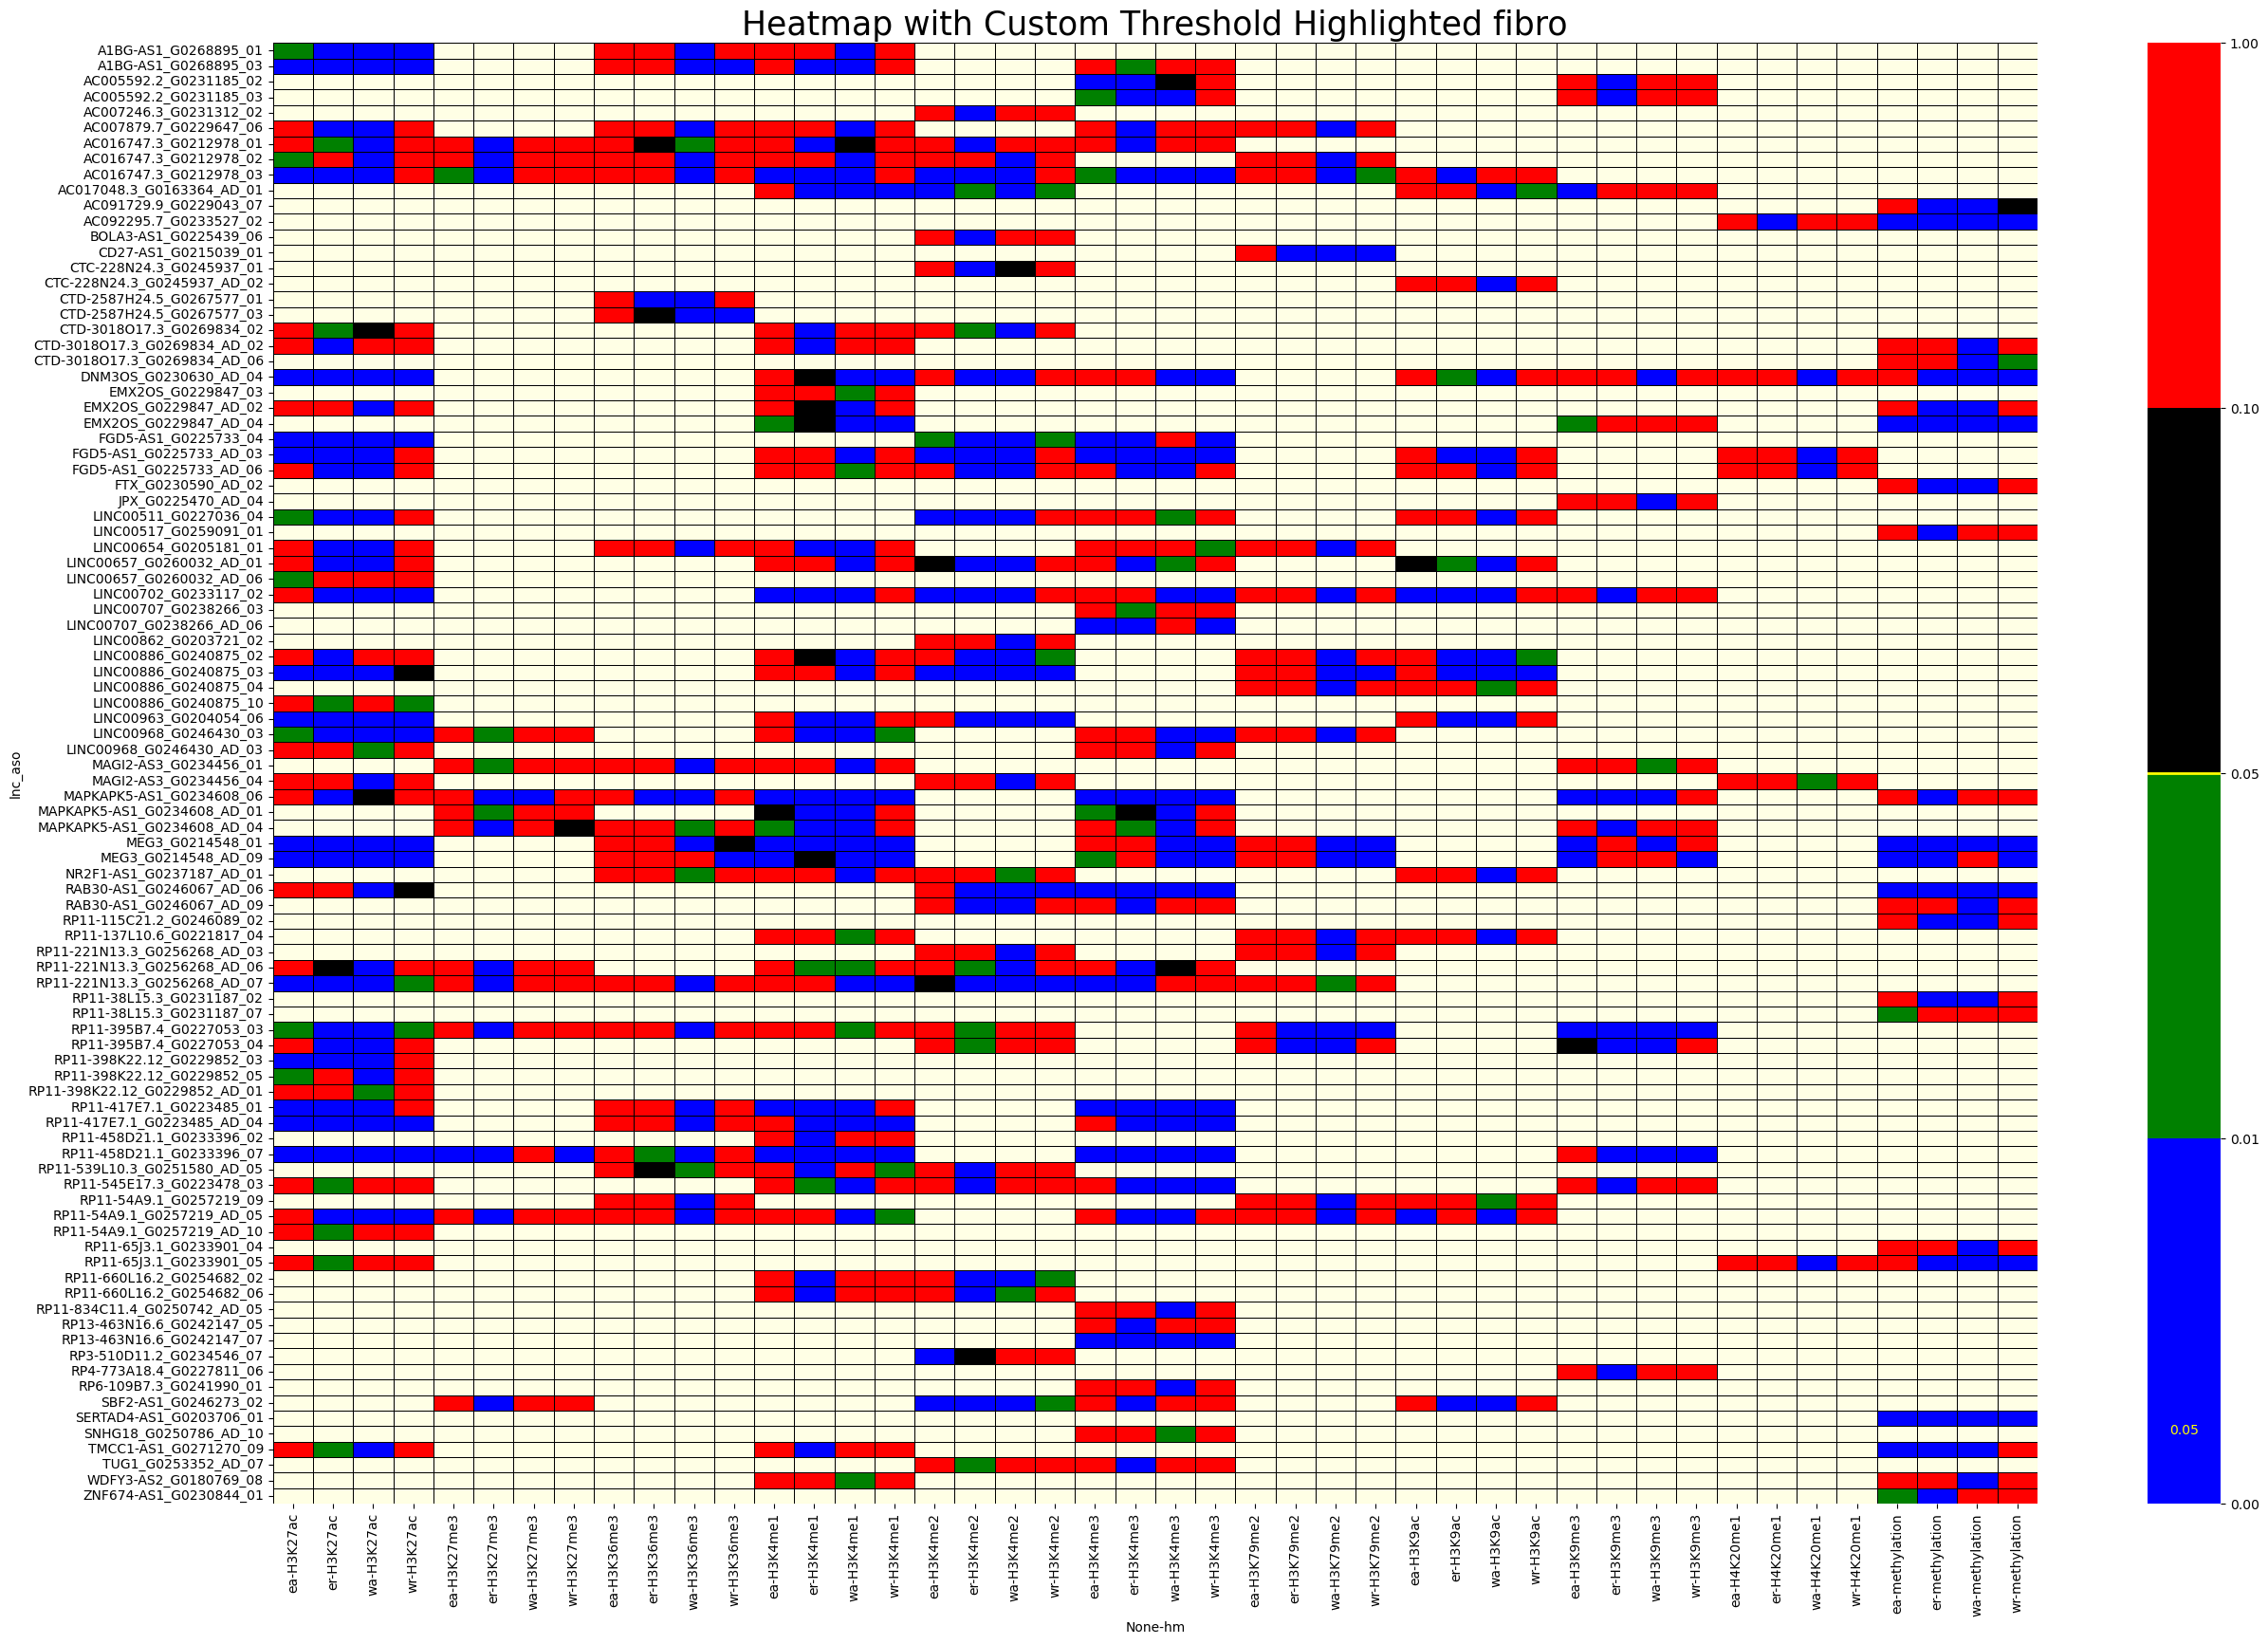

In [103]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp["fibro"], exp="fibro")

/tmp/ipykernel_3780408/4239145872.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["lnc_aso"] = df["lnc"] + "_" + df["aso"]


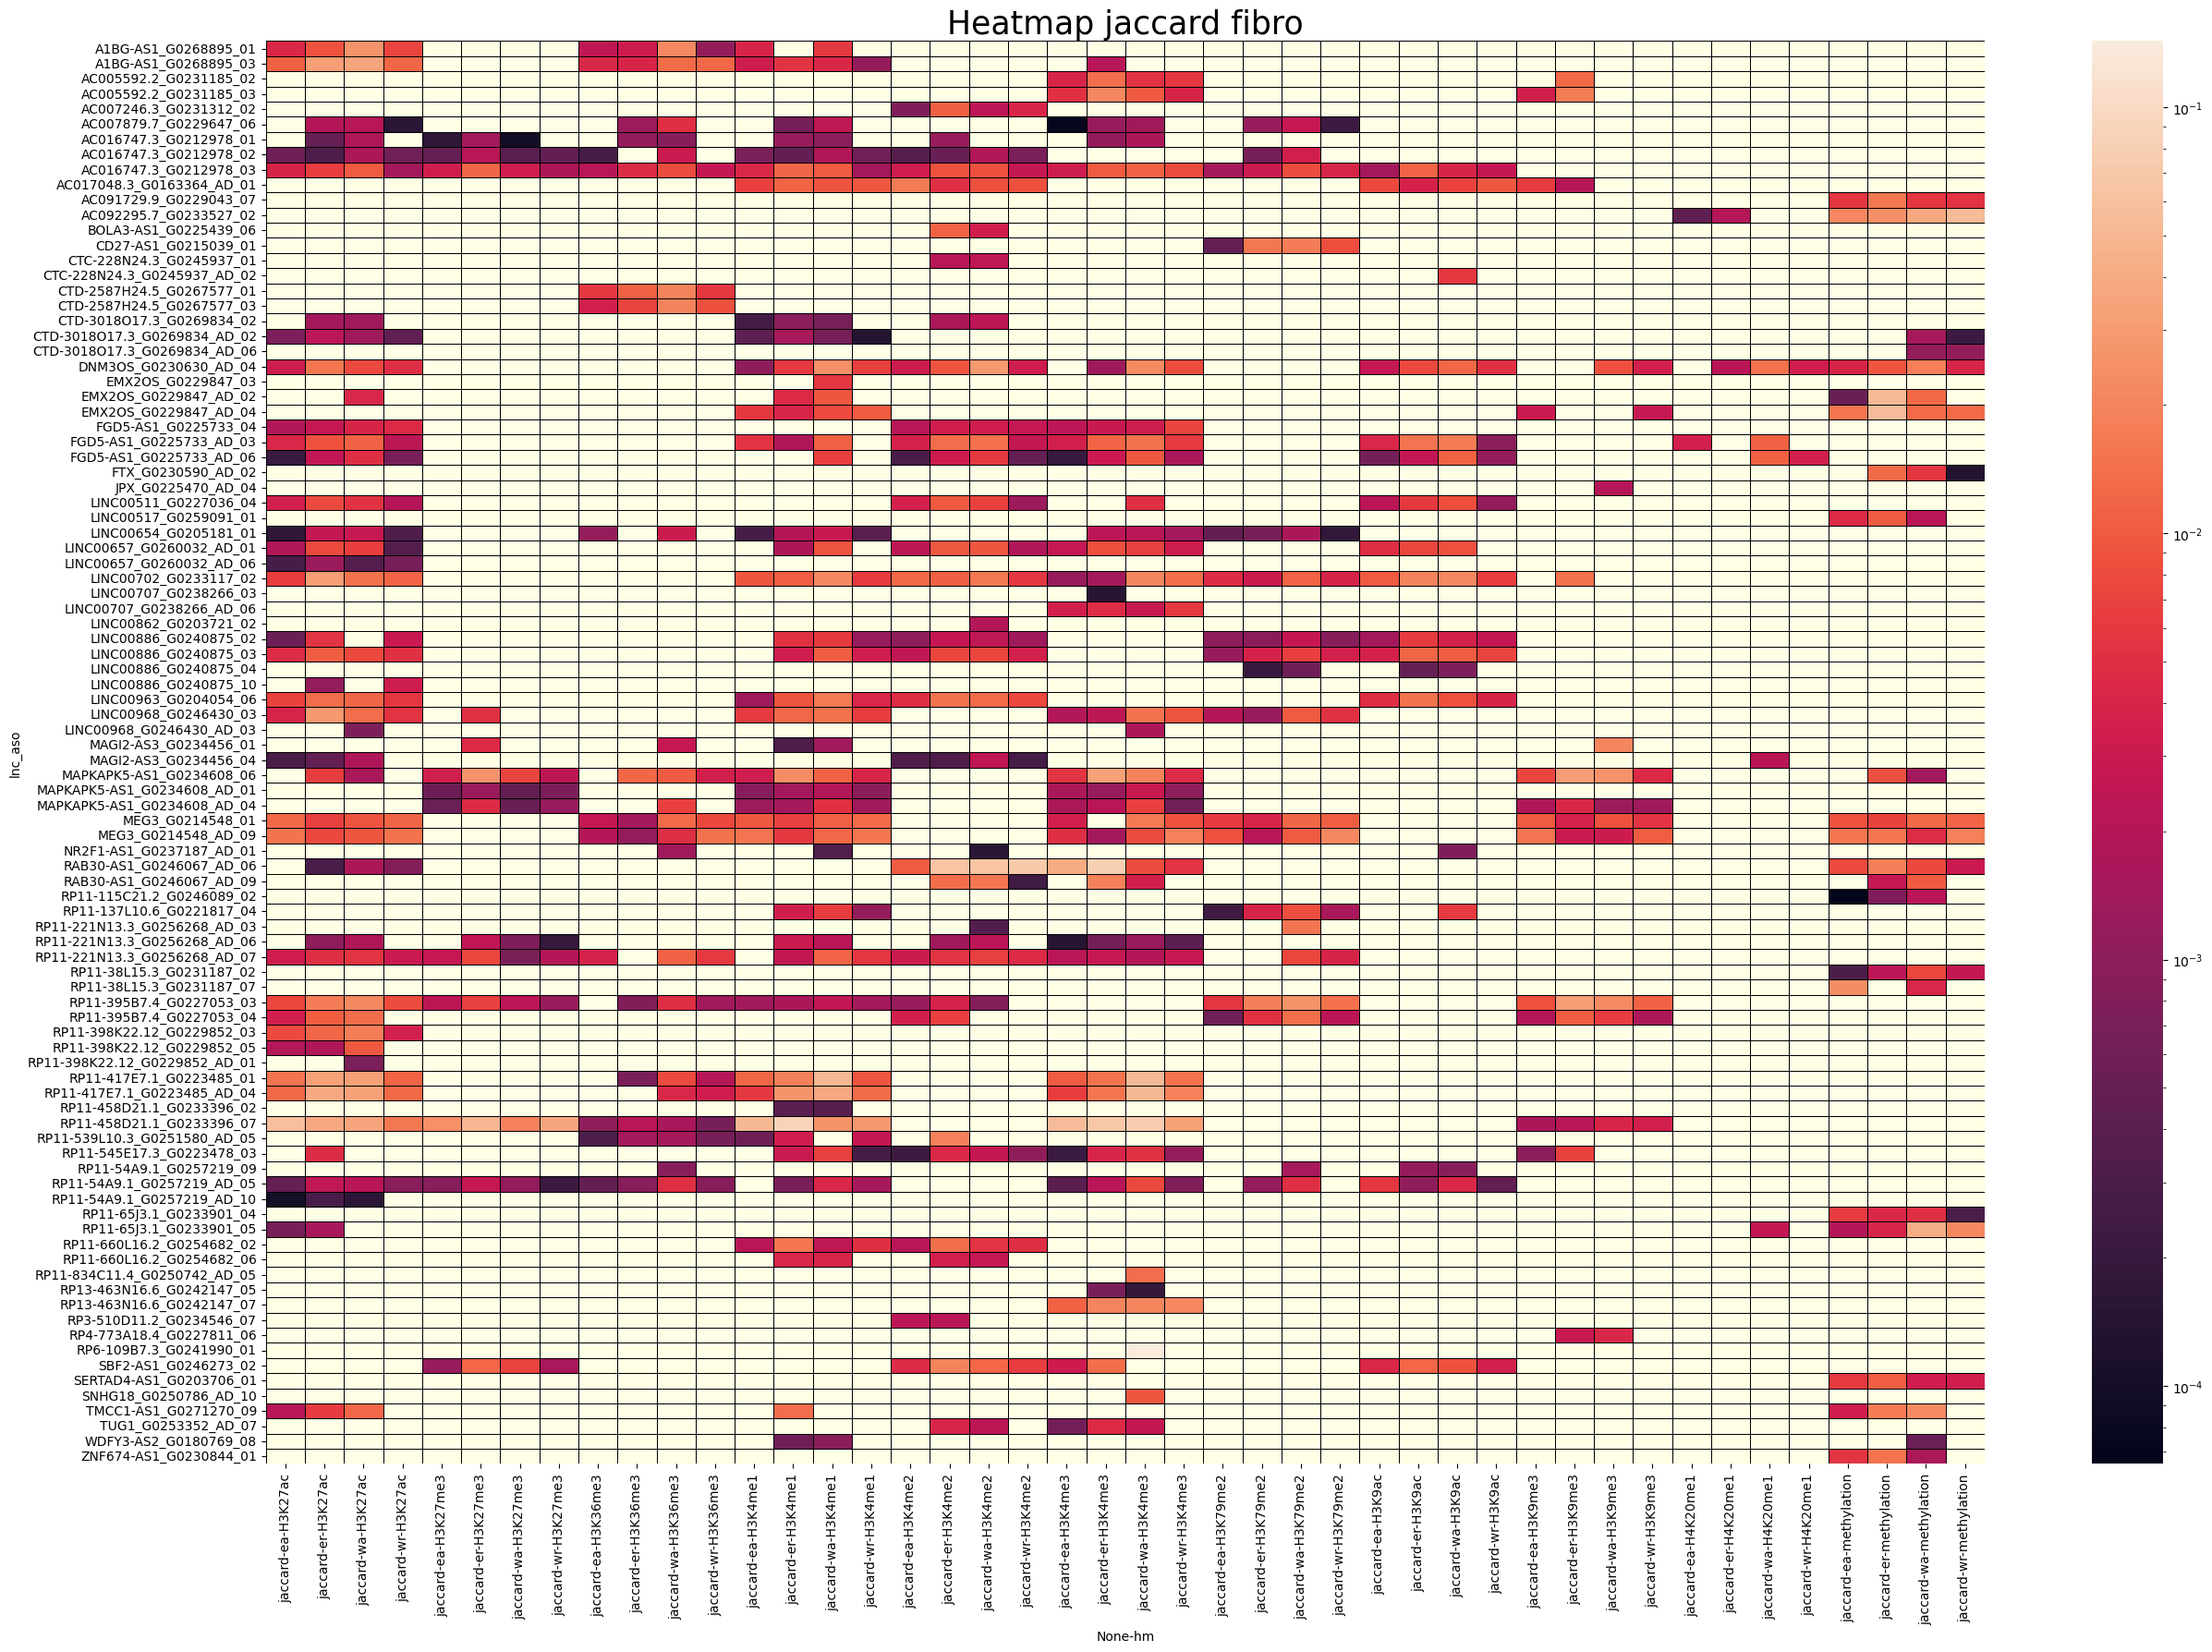

In [141]:
heatmap_pval_blue_red_jaccard(df=jaccard_results_filt_by_exp["fibro"], exp="fibro")

In [35]:
fisher_results_filt_by_exp["ips"]

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm
0,H3K4me3,ENSG00000225975,G0225975_05,1.000000e+00,1.645201e-03,1.000000e+00,1.000000e+00,AC074138.3,AC074138.3-H3K4me3,AC074138.3-G0225975_05-H3K4me3
1,H3K4me3,ENSG00000234608,G0234608_03,2.363291e-03,1.000000e+00,5.232568e-02,1.297265e-12,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_03-H3K4me3
2,H3K4me3,ENSG00000234608,G0234608_AD_08,1.000000e+00,1.000000e+00,1.086221e-08,1.000000e+00,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_AD_08-H3K4me3
3,H3K4me3,ENSG00000235560,G0235560_01,4.437244e-02,1.000000e+00,1.000000e+00,1.000000e+00,AC002310.12,AC002310.12-H3K4me3,AC002310.12-G0235560_01-H3K4me3
4,H3K4me3,ENSG00000245937,G0245937_01,4.437244e-02,4.663546e-01,1.000000e+00,1.000000e+00,CTC-228N24.3,CTC-228N24.3-H3K4me3,CTC-228N24.3-G0245937_01-H3K4me3
5,H3K4me3,ENSG00000247556,G0247556_09,1.255939e-08,6.754636e-10,1.000000e+00,1.000000e+00,OIP5-AS1,OIP5-AS1-H3K4me3,OIP5-AS1-G0247556_09-H3K4me3
6,methylation,ENSG00000225484,G0225484_02,1.000000e+00,1.000000e+00,4.000629e-02,1.000000e+00,RP11-773D16.1,RP11-773D16.1-methylation,RP11-773D16.1-G0225484_02-methylation
7,methylation,ENSG00000229153,G0229153_09,2.711532e-01,1.442290e-04,1.940174e-01,6.586324e-01,EPHA1-AS1,EPHA1-AS1-methylation,EPHA1-AS1-G0229153_09-methylation
8,methylation,ENSG00000230844,G0230844_AD_07,1.000000e+00,1.145524e-03,7.588105e-01,7.732718e-01,ZNF674-AS1,ZNF674-AS1-methylation,ZNF674-AS1-G0230844_AD_07-methylation
9,H3K9ac,ENSG00000196668,G0196668_08,1.000000e+00,1.000000e+00,7.050809e-03,1.000000e+00,LINC00173,LINC00173-H3K9ac,LINC00173-G0196668_08-H3K9ac


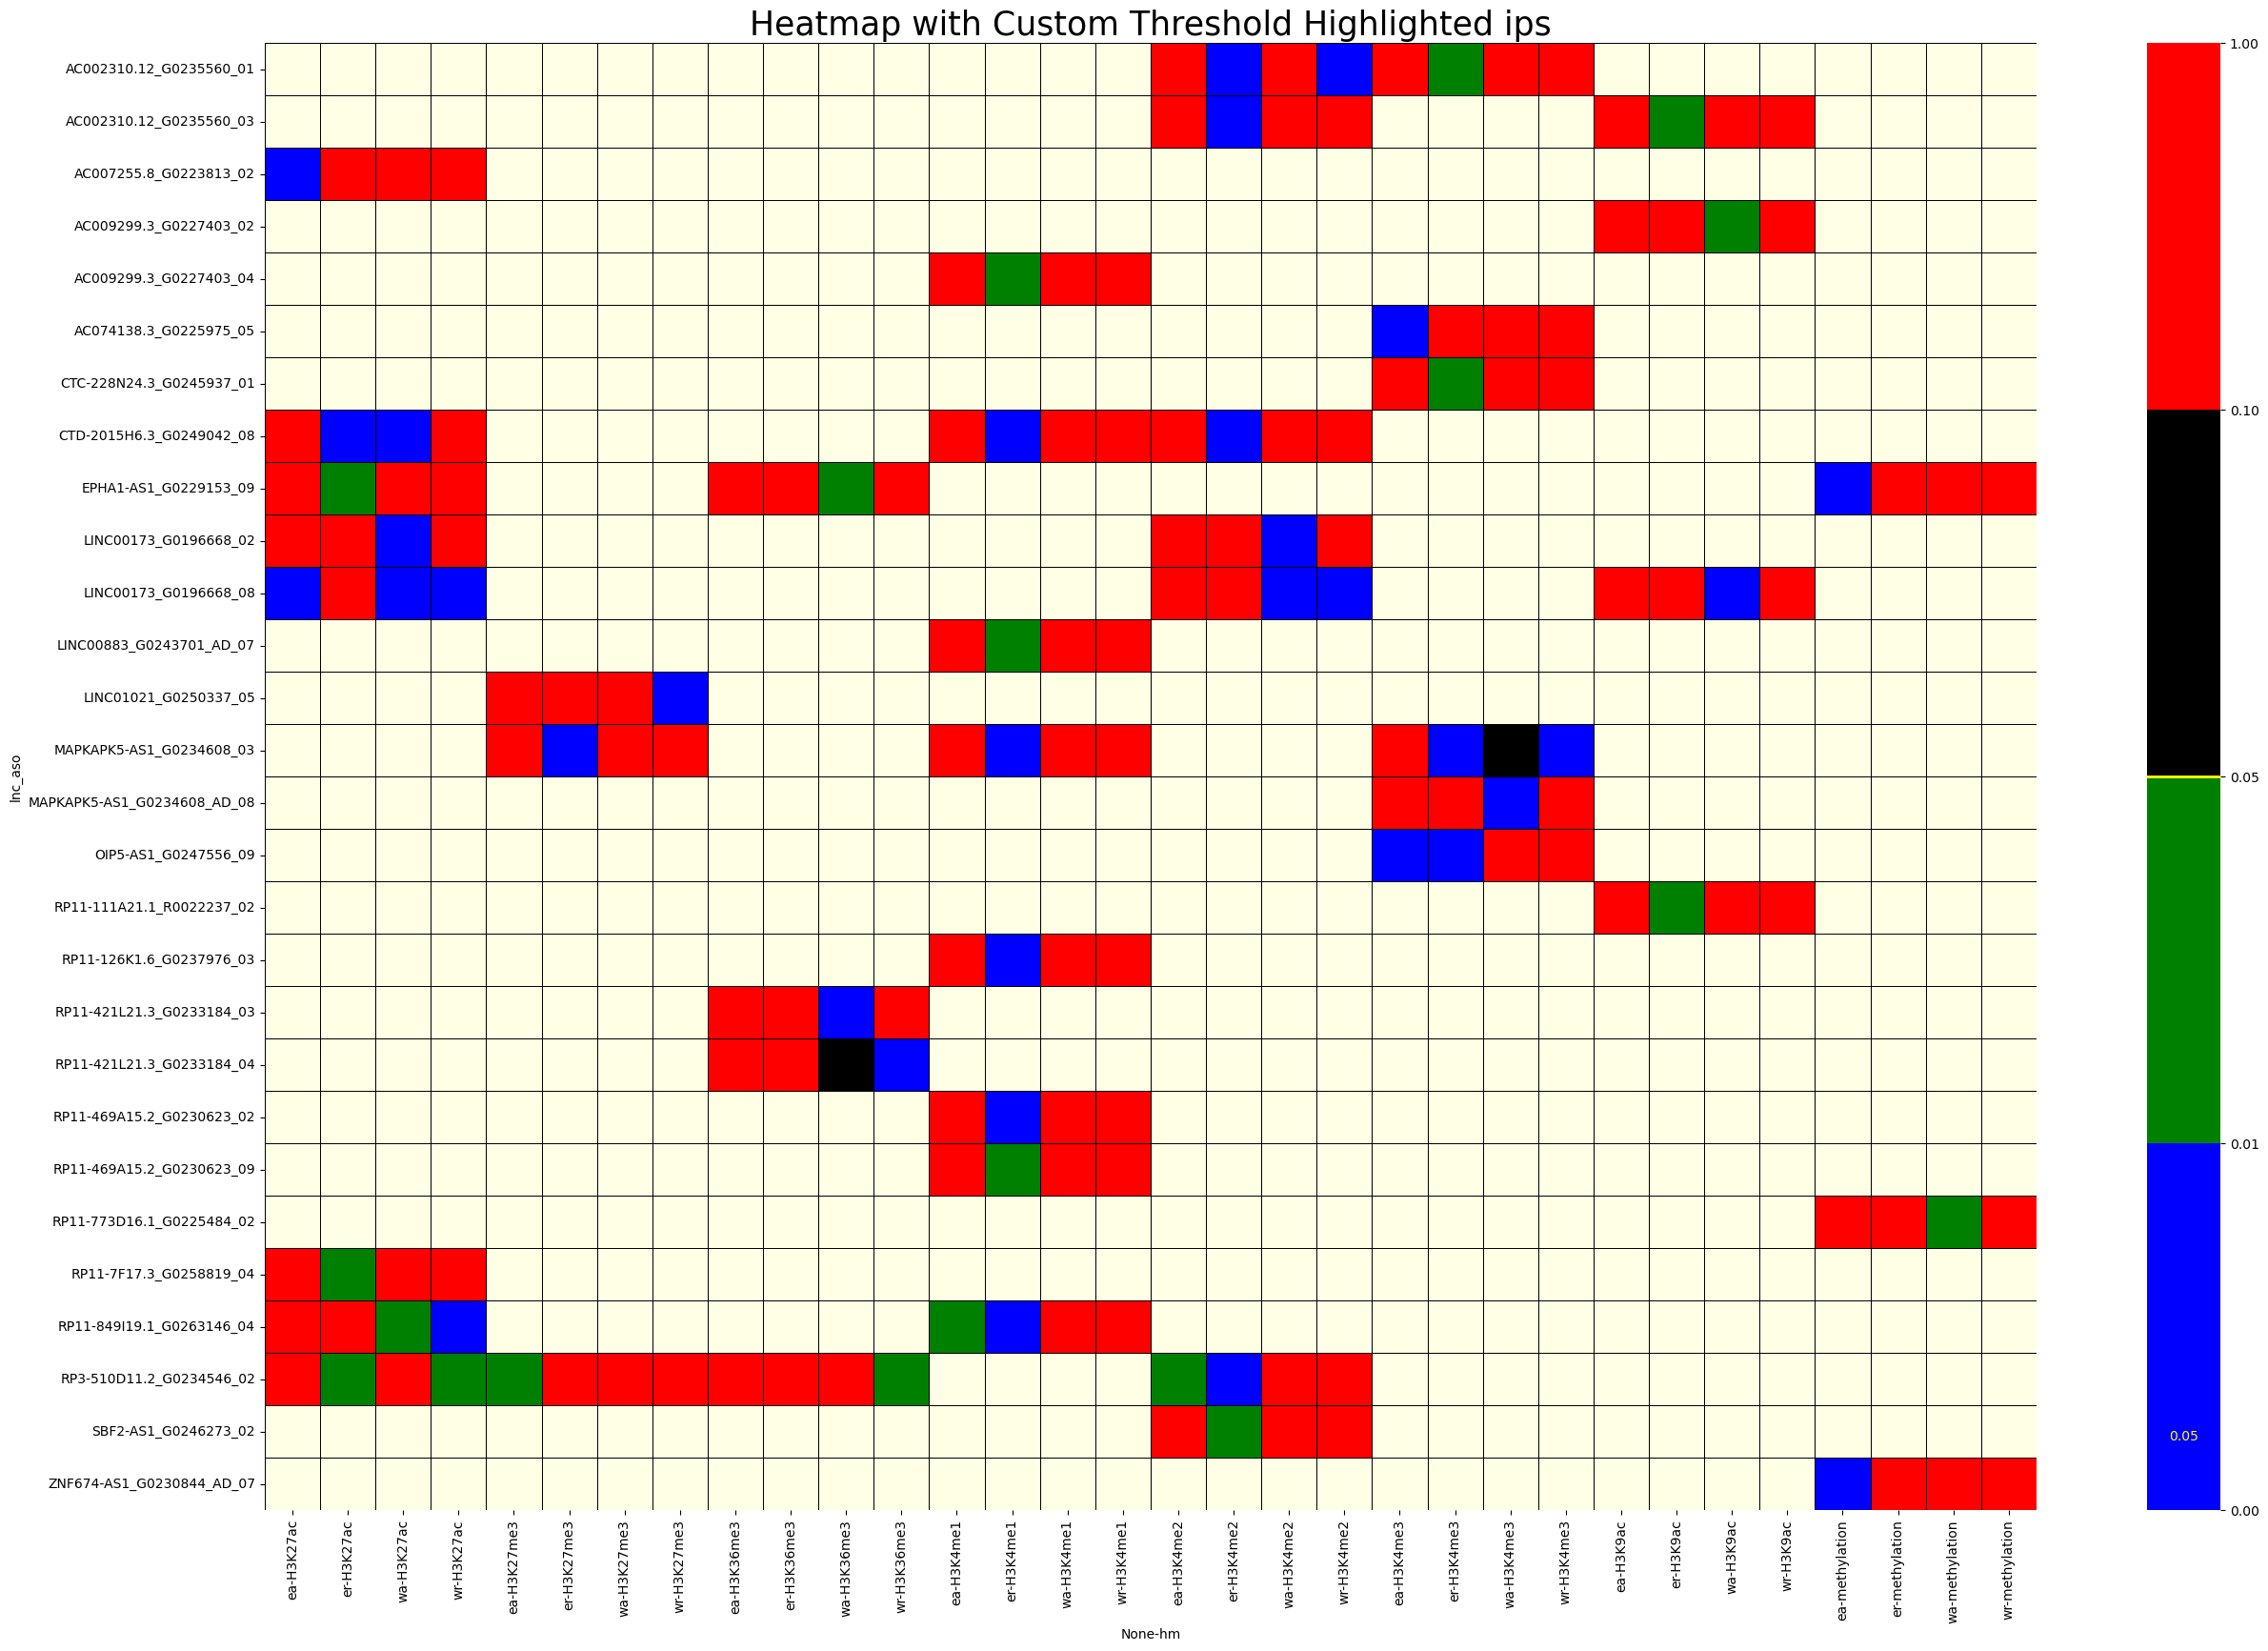

In [7]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp["ips"], exp="ips")

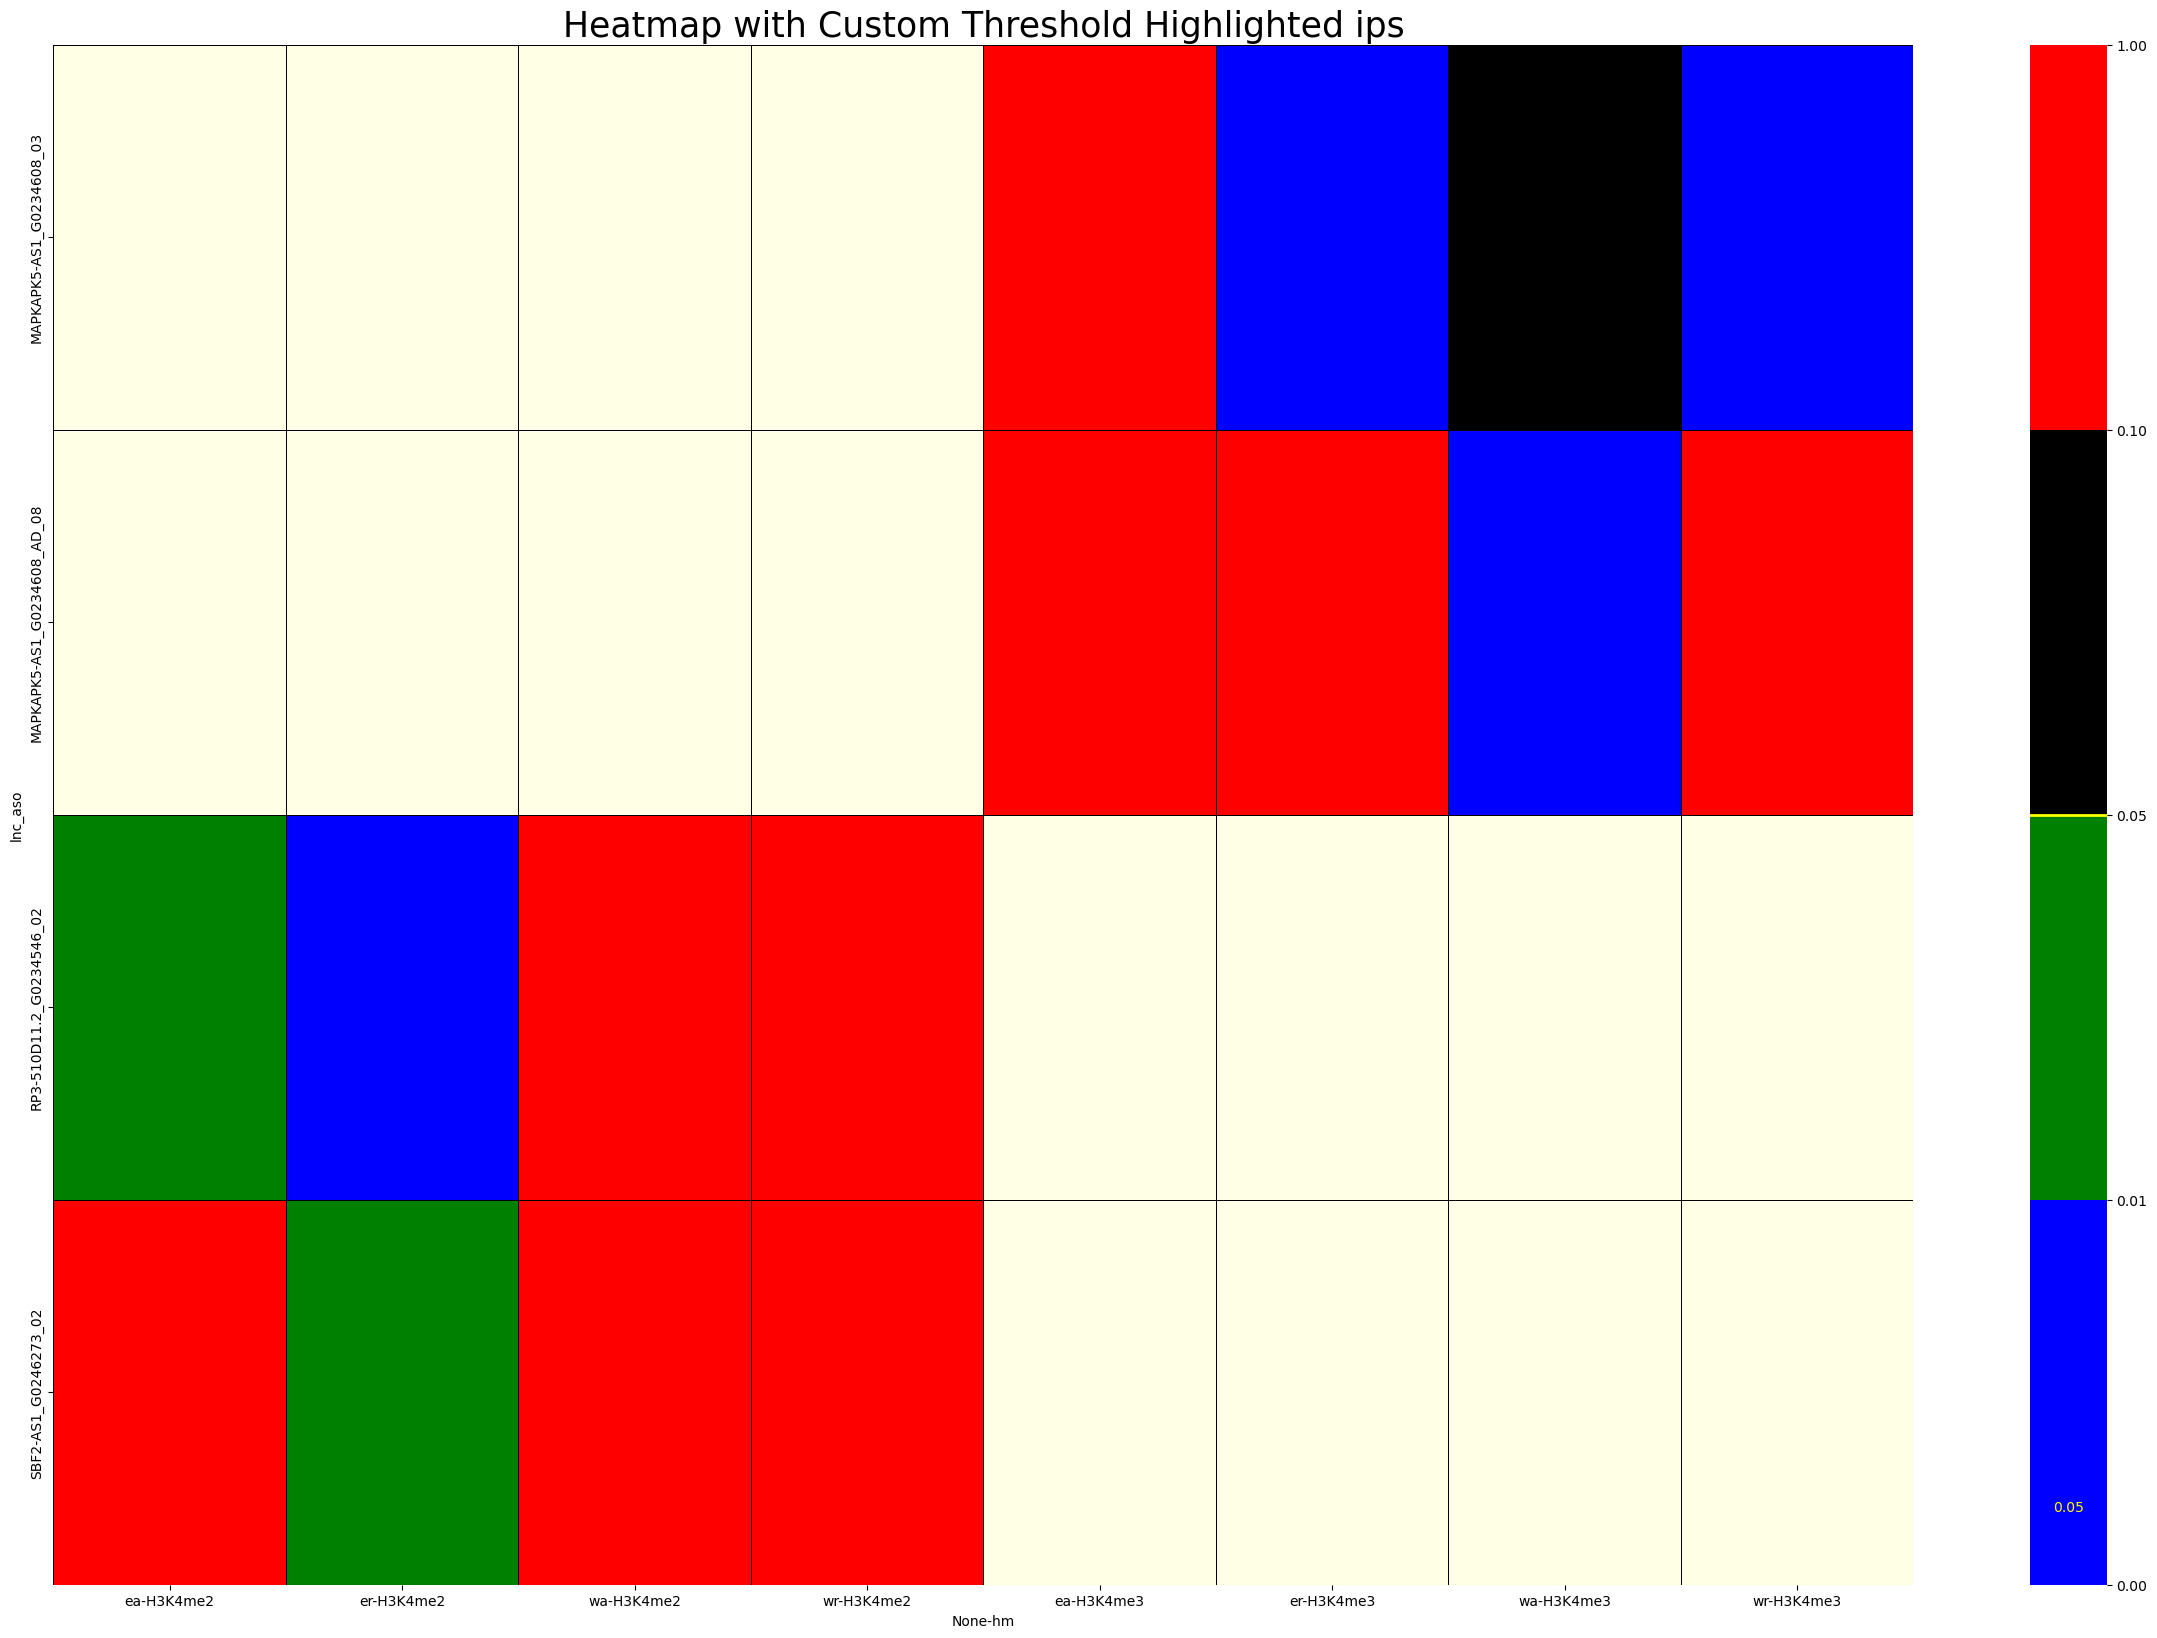

In [29]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp_bootstraped["ips"], exp="ips")

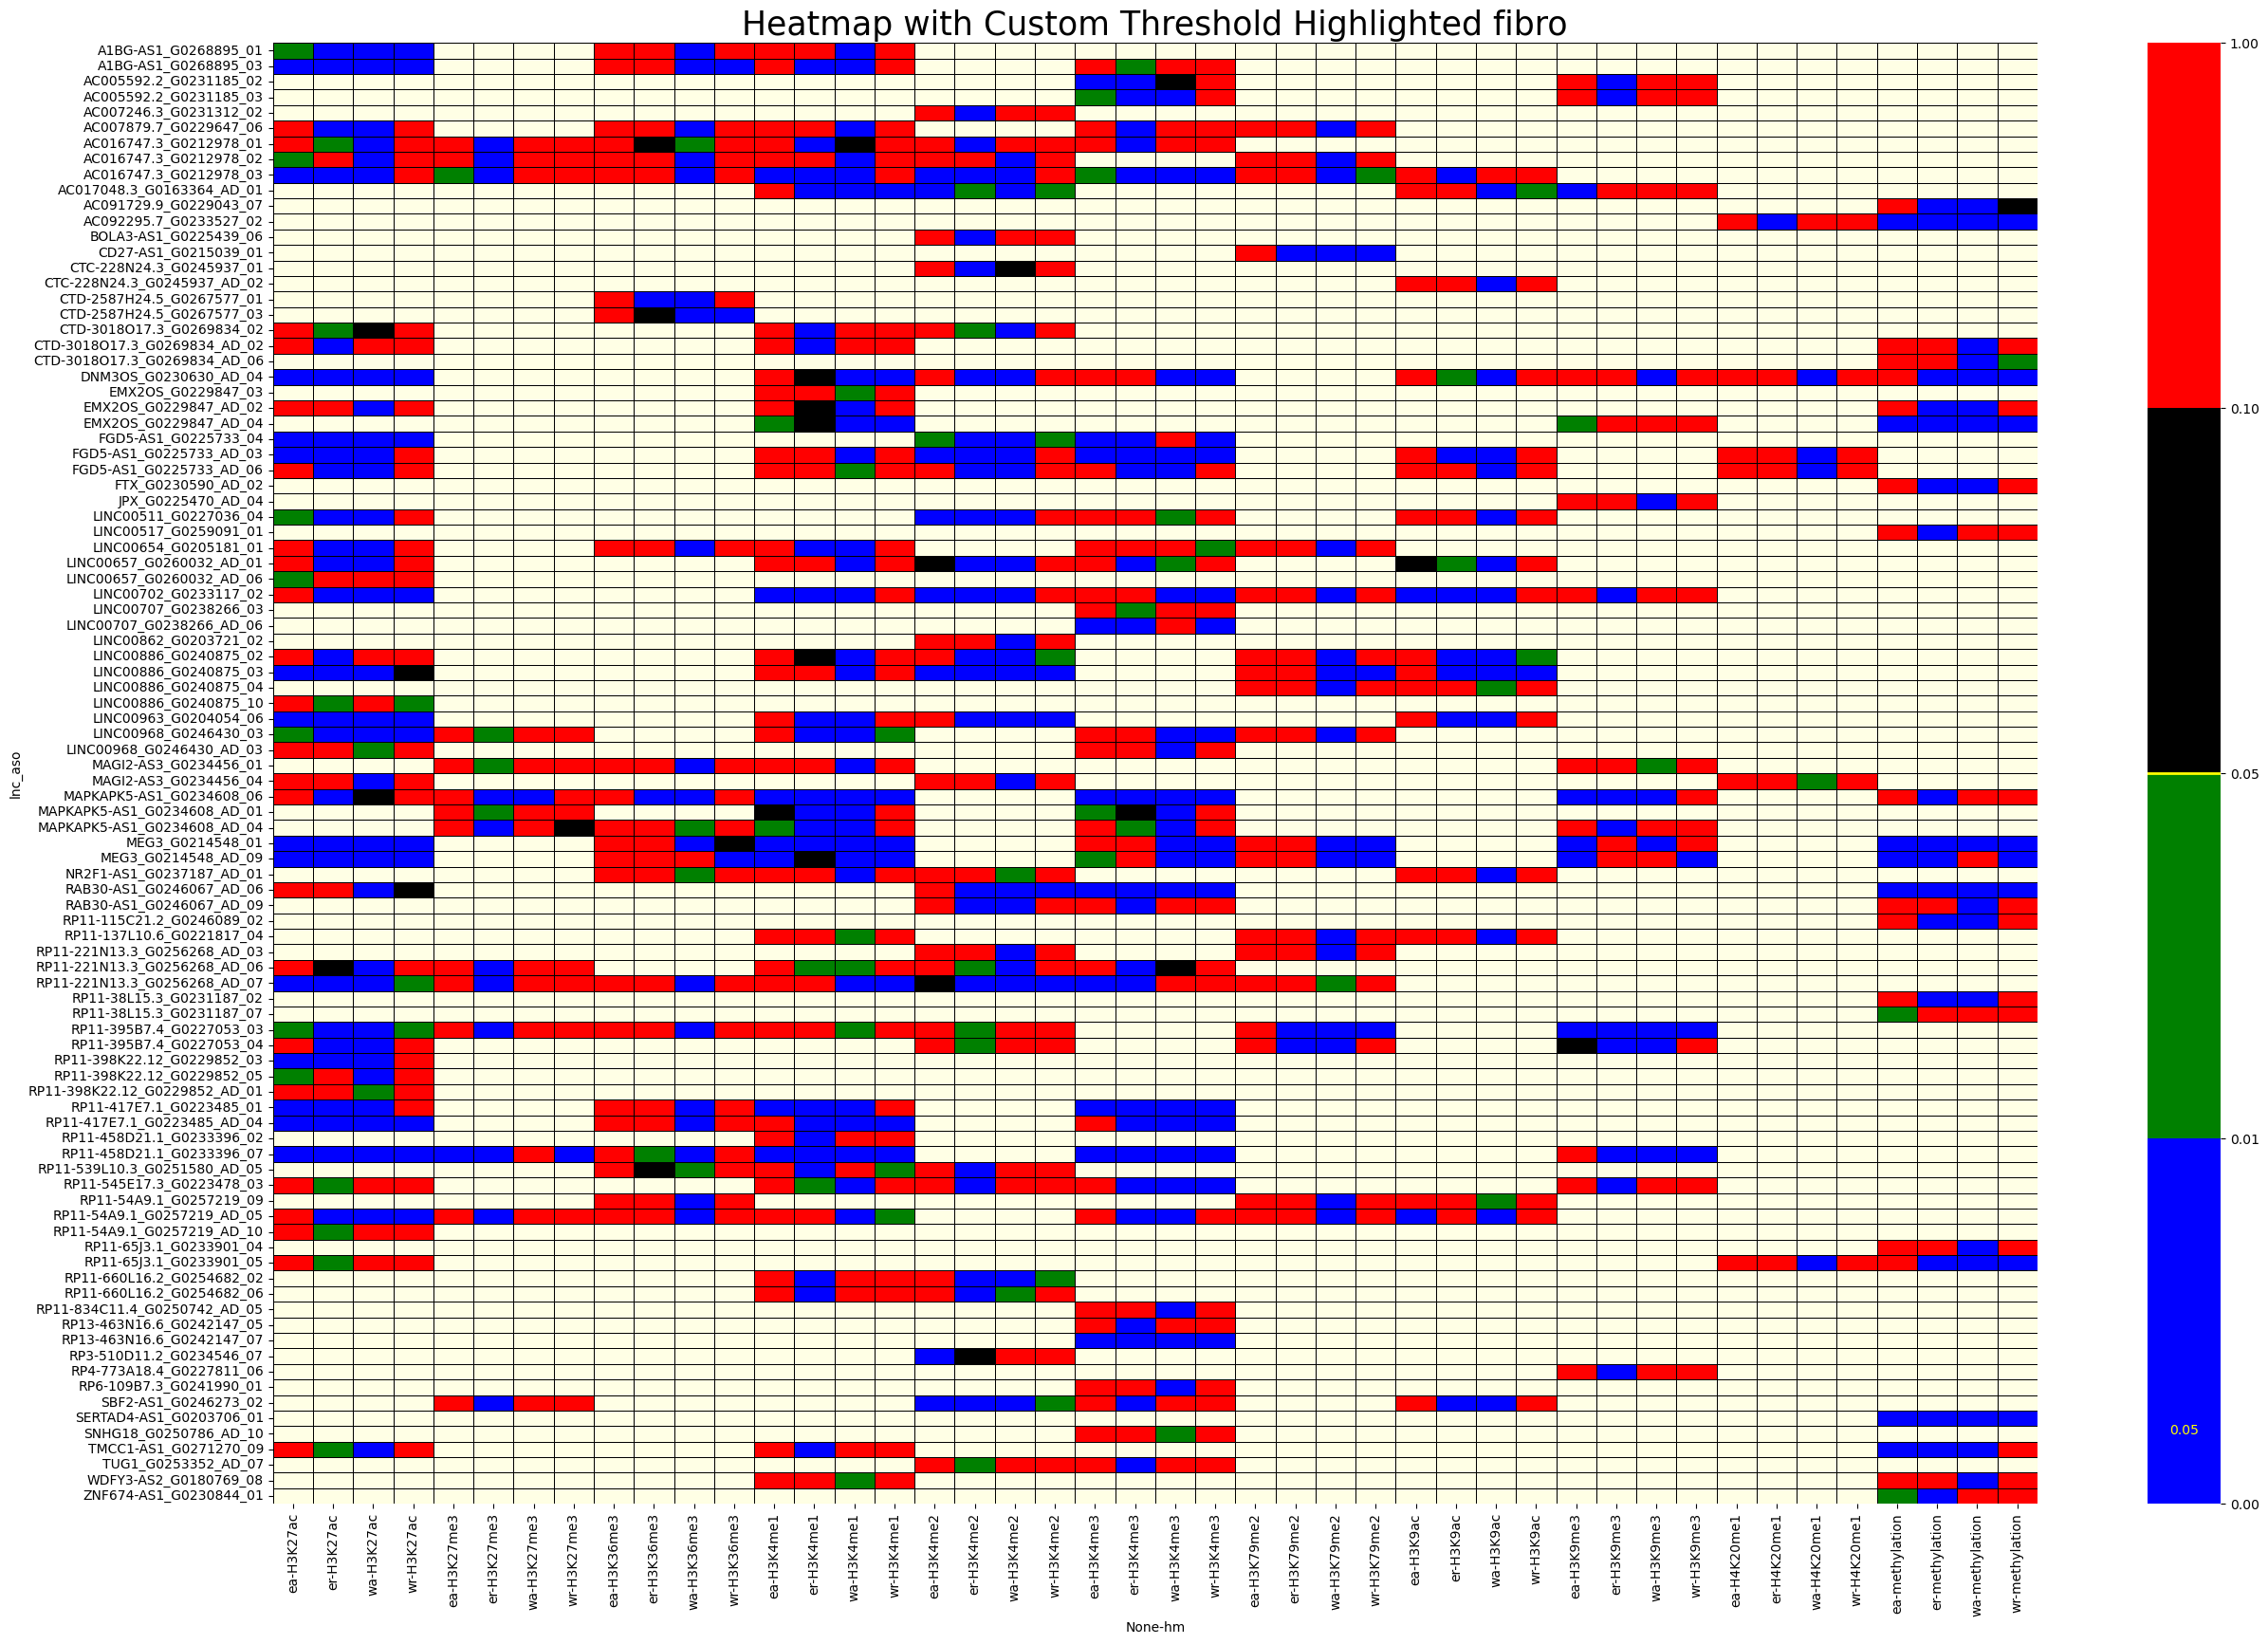

In [12]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp["fibro"], exp="fibro")

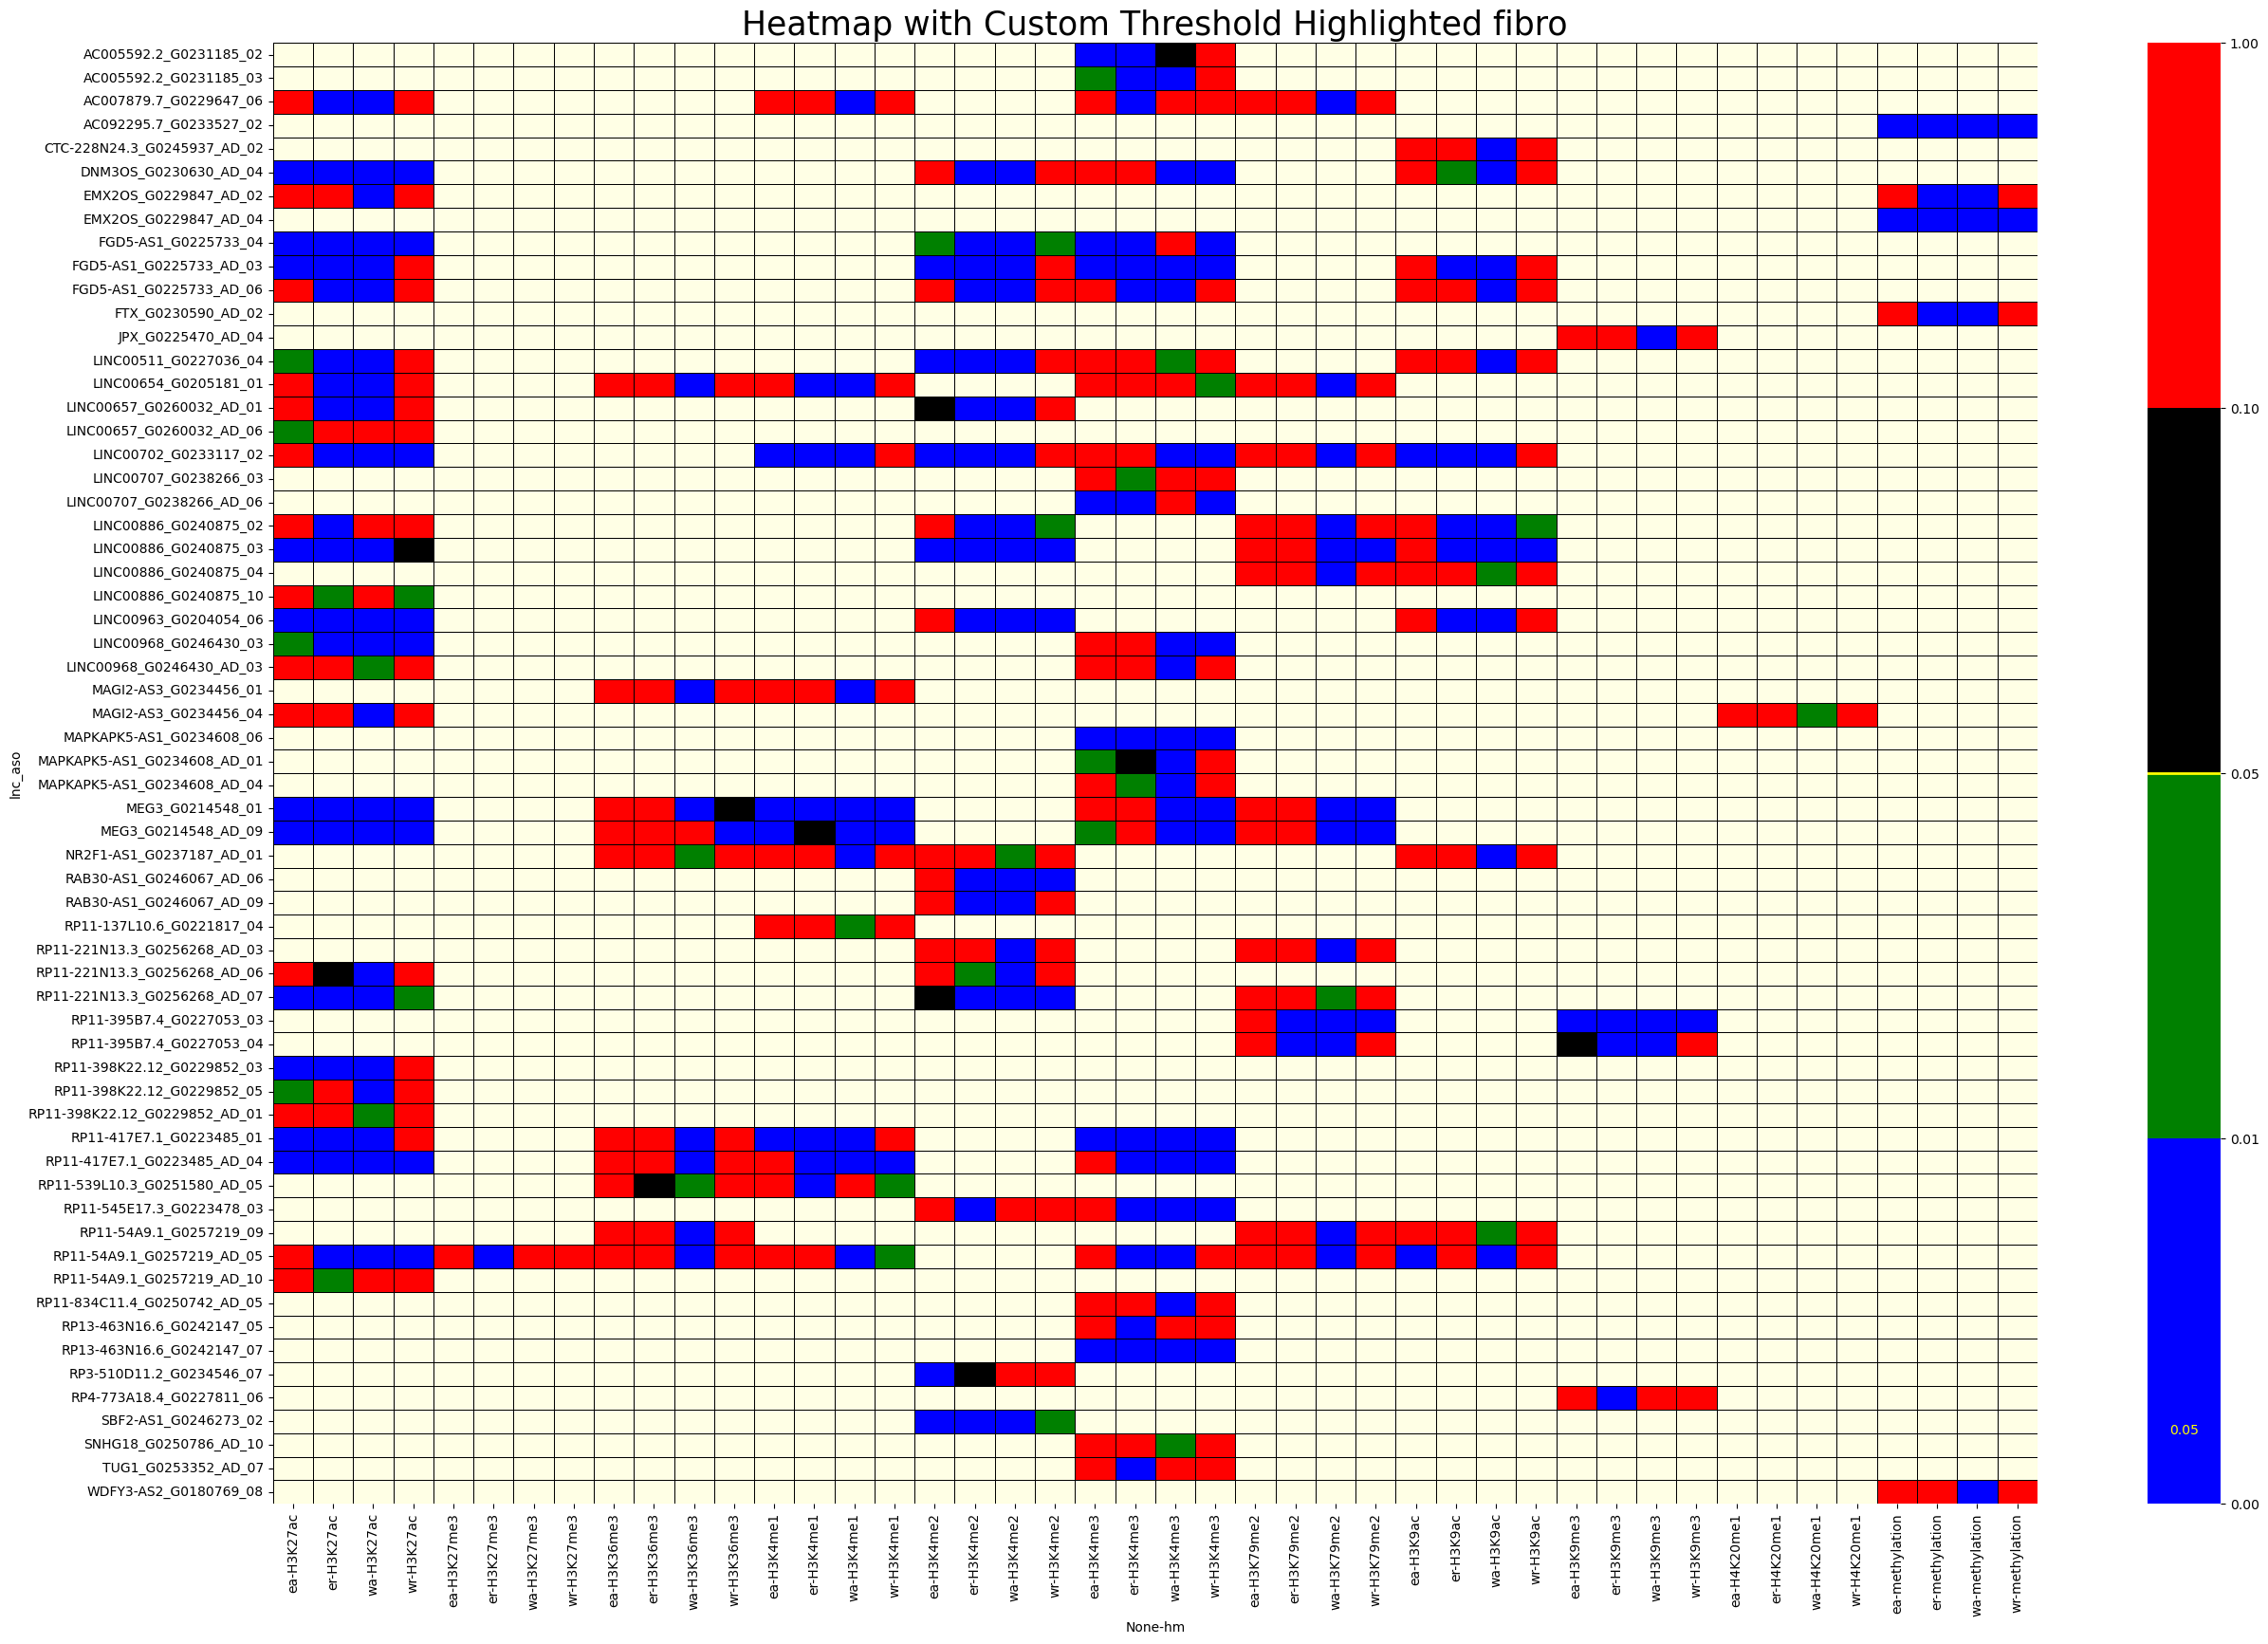

In [30]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp_bootstraped["fibro"], exp="fibro")

/tmp/ipykernel_32521/4239145872.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["lnc_aso"] = df["lnc"] + "_" + df["aso"]


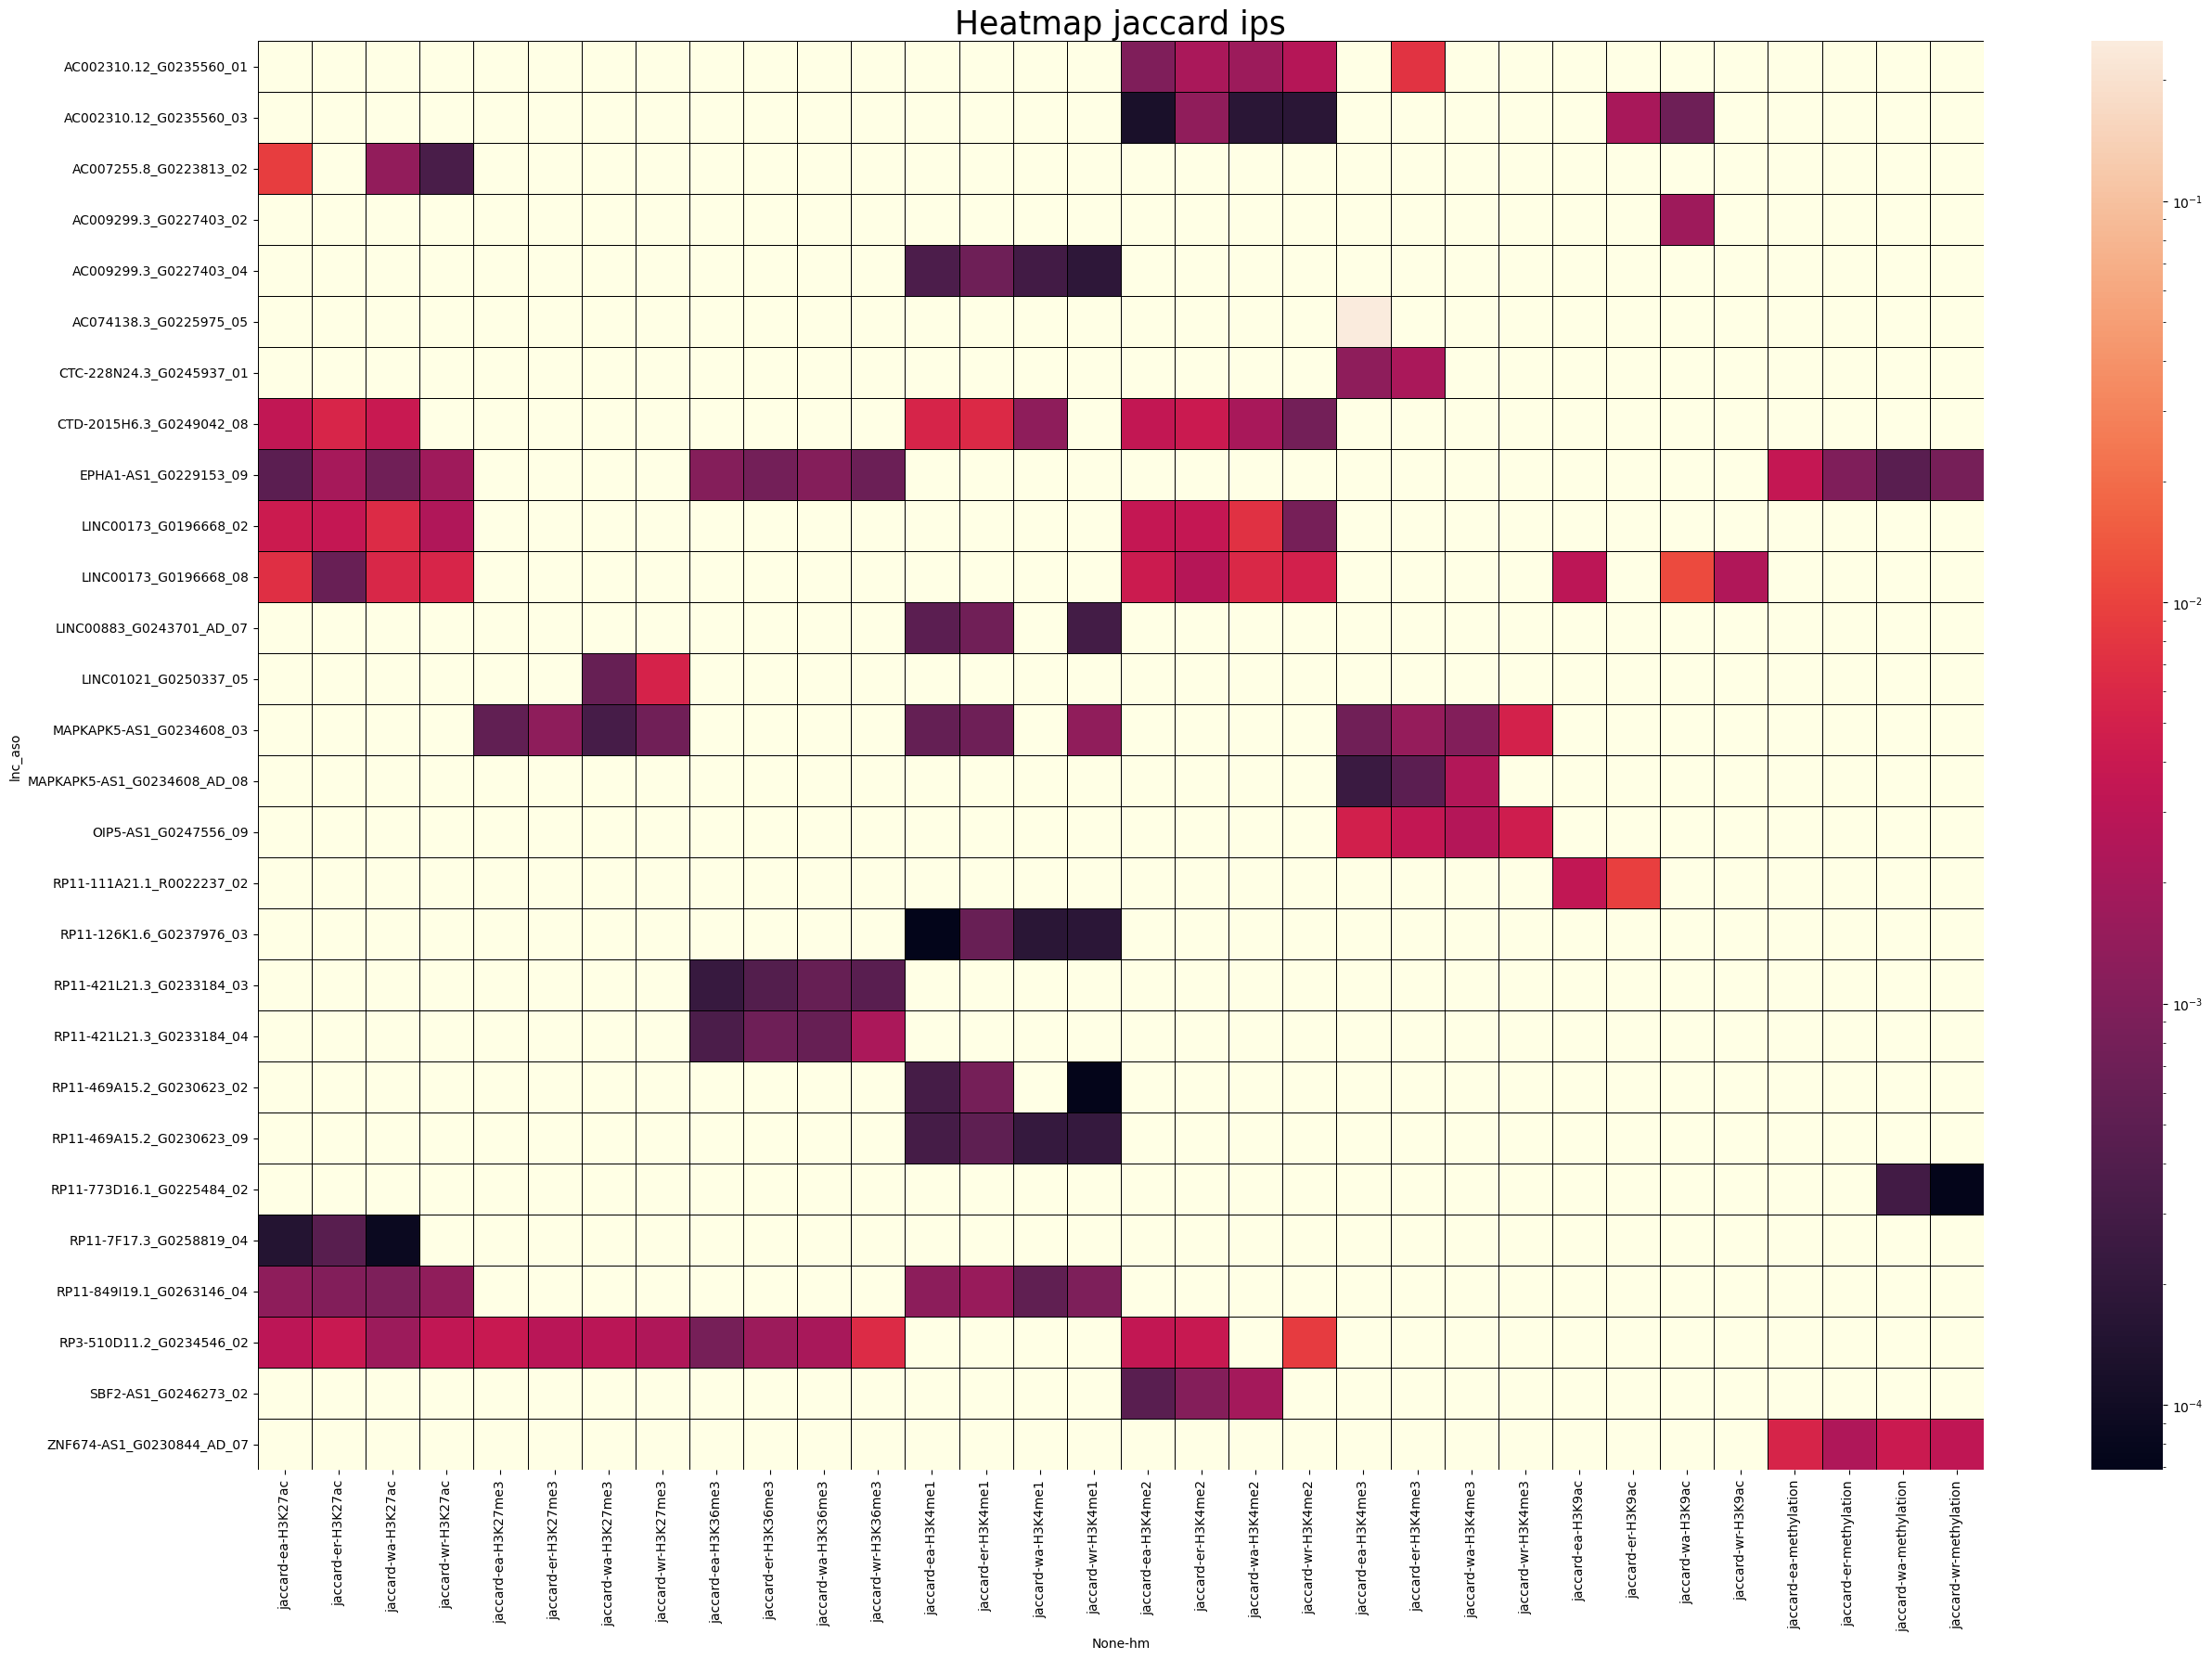

In [11]:
heatmap_pval_blue_red_jaccard(df=jaccard_results_filt_by_exp["ips"], exp="ips")

## Сравнение результатов между ASO в пределах одной ткани

In [281]:
fisher_results_filt_two_aso_by_exp = defaultdict(list)
for exp in ["fibro", "ips"]:
    for (lnc_hm, subdf) in fisher_results_filt_by_exp[exp].groupby(by="lnc-hm"):
        if len(subdf) >= 2:
            mask_er = np.where(subdf["er"] < 0.05, True, False)
            mask_ea = np.where(subdf["ea"] < 0.05, True, False)
            mask_wa = np.where(subdf["wa"] < 0.05, True, False)
            mask_wr = np.where(subdf["wr"] < 0.05, True, False)
            mask = np.where(np.array([mask_er, mask_ea, mask_wa, mask_wr]).sum(axis=1) >= 2, True, False)
            if mask.sum() >=1 :
                fisher_results_filt_two_aso_by_exp[exp].append(subdf)
            #mask = mask_er | mask_ea | mask_wa | mask_wr
            #if mask.sum() >= 2:
            #    fisher_results_filt_two_aso_by_exp[exp].append(subdf[mask])
            #if lnc_hm == "MAPKAPK5-AS1-H3K4me3":
                #break
    if len(fisher_results_filt_two_aso_by_exp[exp]) >= 1:
        fisher_results_filt_two_aso_by_exp[exp] = pd.concat(fisher_results_filt_two_aso_by_exp[exp])

In [282]:
np.where(np.array([mask_er, mask_ea, mask_wa, mask_wr]).sum(axis=1) >= 2, True, False)

array([ True, False, False, False])

In [283]:
np.array([mask_er, mask_ea, mask_wa, mask_wr])

array([[ True,  True],
       [False, False],
       [False, False],
       [False, False]])

In [284]:
np.array([mask_er, mask_ea, mask_wa, mask_wr]).sum(axis=0)

array([1, 1])

In [285]:
subdf

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm,lnc_aso
8,methylation,ENSG00000230844,G0230844_AD_07,1.0,0.001146,0.758811,0.773272,ZNF674-AS1,ZNF674-AS1-methylation,ZNF674-AS1-G0230844_AD_07-methylation,ZNF674-AS1_G0230844_AD_07


In [286]:
mask_er | mask_ea | mask_wa | mask_wr

array([ True,  True])

In [287]:
fisher_results_filt_two_aso_by_exp["ips"]

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm,lnc_aso
16,H3K4me2,ENSG00000235560,G0235560_01,0.000215,1.000000,1.124345e-01,0.004047,AC002310.12,AC002310.12-H3K4me2,AC002310.12-G0235560_01-H3K4me2,AC002310.12_G0235560_01
17,H3K4me2,ENSG00000235560,G0235560_03,0.000011,1.000000,1.000000e+00,1.000000,AC002310.12,AC002310.12-H3K4me2,AC002310.12-G0235560_03-H3K4me2,AC002310.12_G0235560_03
27,H3K27ac,ENSG00000196668,G0196668_02,0.393249,0.143507,6.696299e-08,0.794276,LINC00173,LINC00173-H3K27ac,LINC00173-G0196668_02-H3K27ac,LINC00173_G0196668_02
28,H3K27ac,ENSG00000196668,G0196668_08,1.000000,0.001563,8.765851e-07,0.000261,LINC00173,LINC00173-H3K27ac,LINC00173-G0196668_08-H3K27ac,LINC00173_G0196668_08
13,H3K4me2,ENSG00000196668,G0196668_02,0.329076,0.622662,6.015796e-09,1.000000,LINC00173,LINC00173-H3K4me2,LINC00173-G0196668_02-H3K4me2,LINC00173_G0196668_02
14,H3K4me2,ENSG00000196668,G0196668_08,0.735395,0.522237,5.228175e-07,0.007464,LINC00173,LINC00173-H3K4me2,LINC00173-G0196668_08-H3K4me2,LINC00173_G0196668_08
36,H3K4me1,ENSG00000230623,G0230623_02,0.004966,0.267027,1.000000e+00,1.000000,RP11-469A15.2,RP11-469A15.2-H3K4me1,RP11-469A15.2-G0230623_02-H3K4me1,RP11-469A15.2_G0230623_02
37,H3K4me1,ENSG00000230623,G0230623_09,0.031364,0.179489,1.000000e+00,0.918733,RP11-469A15.2,RP11-469A15.2-H3K4me1,RP11-469A15.2-G0230623_09-H3K4me1,RP11-469A15.2_G0230623_09


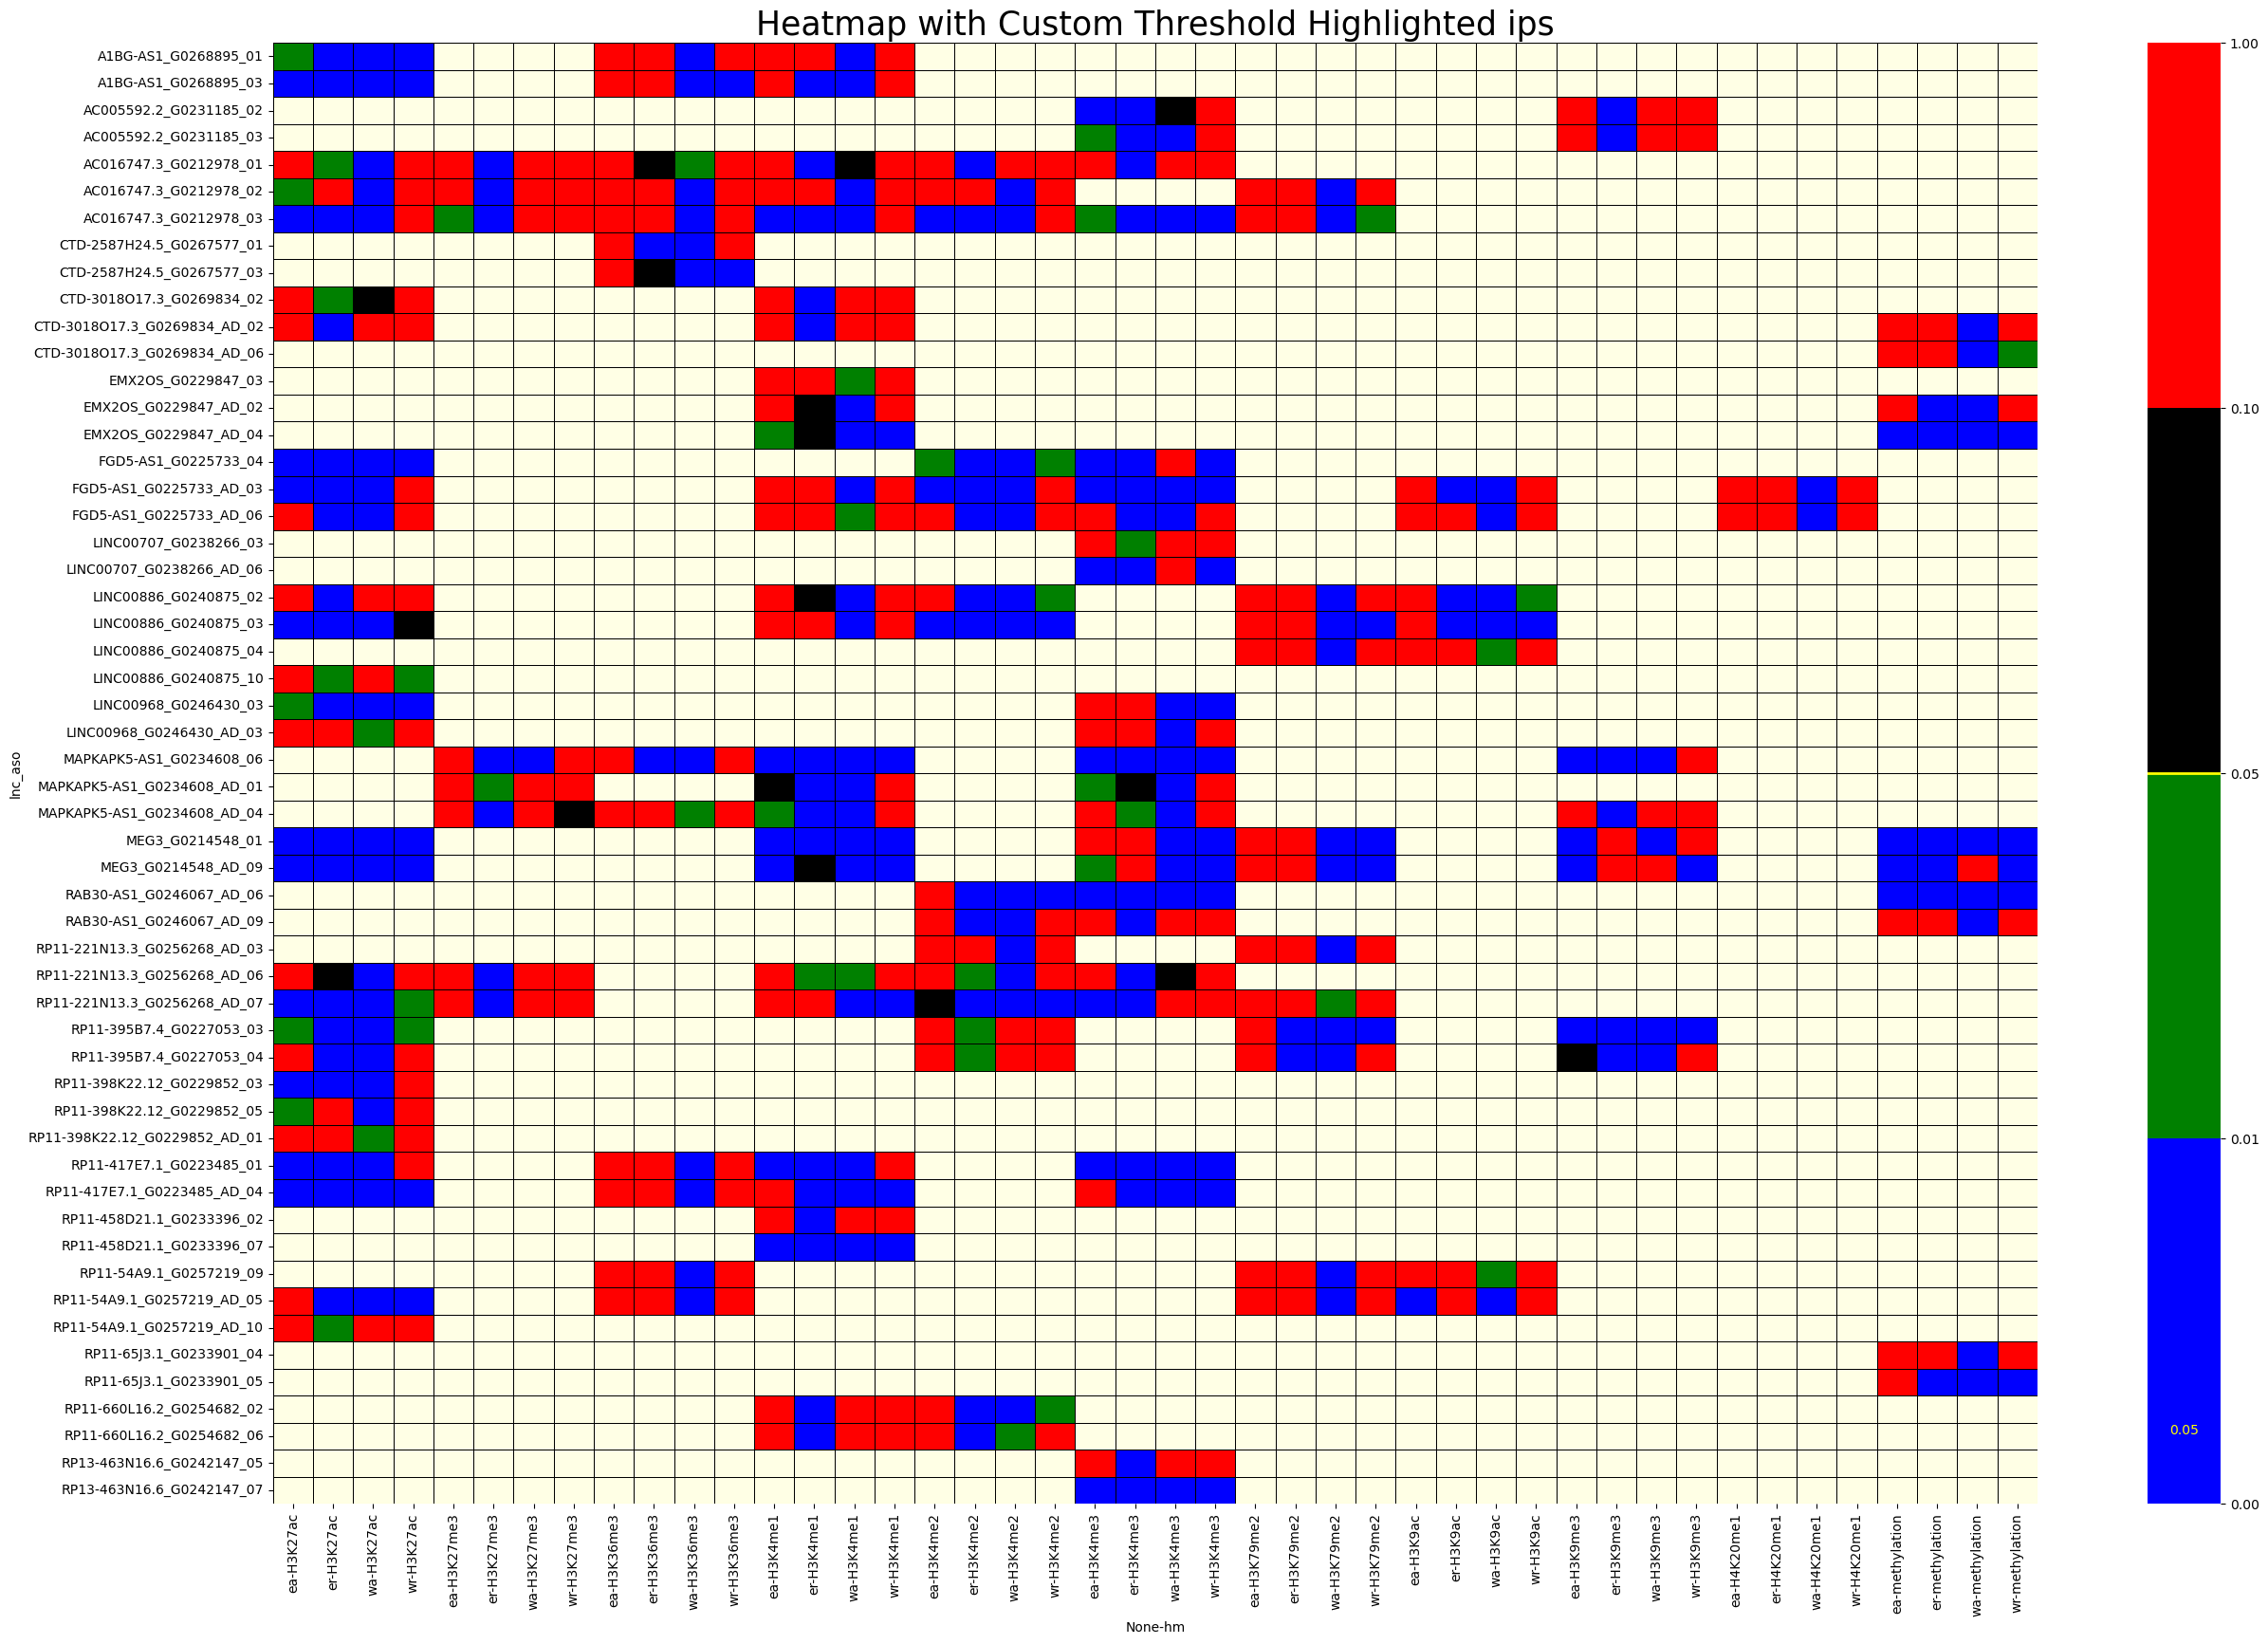

In [289]:
heatmap_pval_blue_red(df=fisher_results_filt_two_aso_by_exp["fibro"], exp="ips")

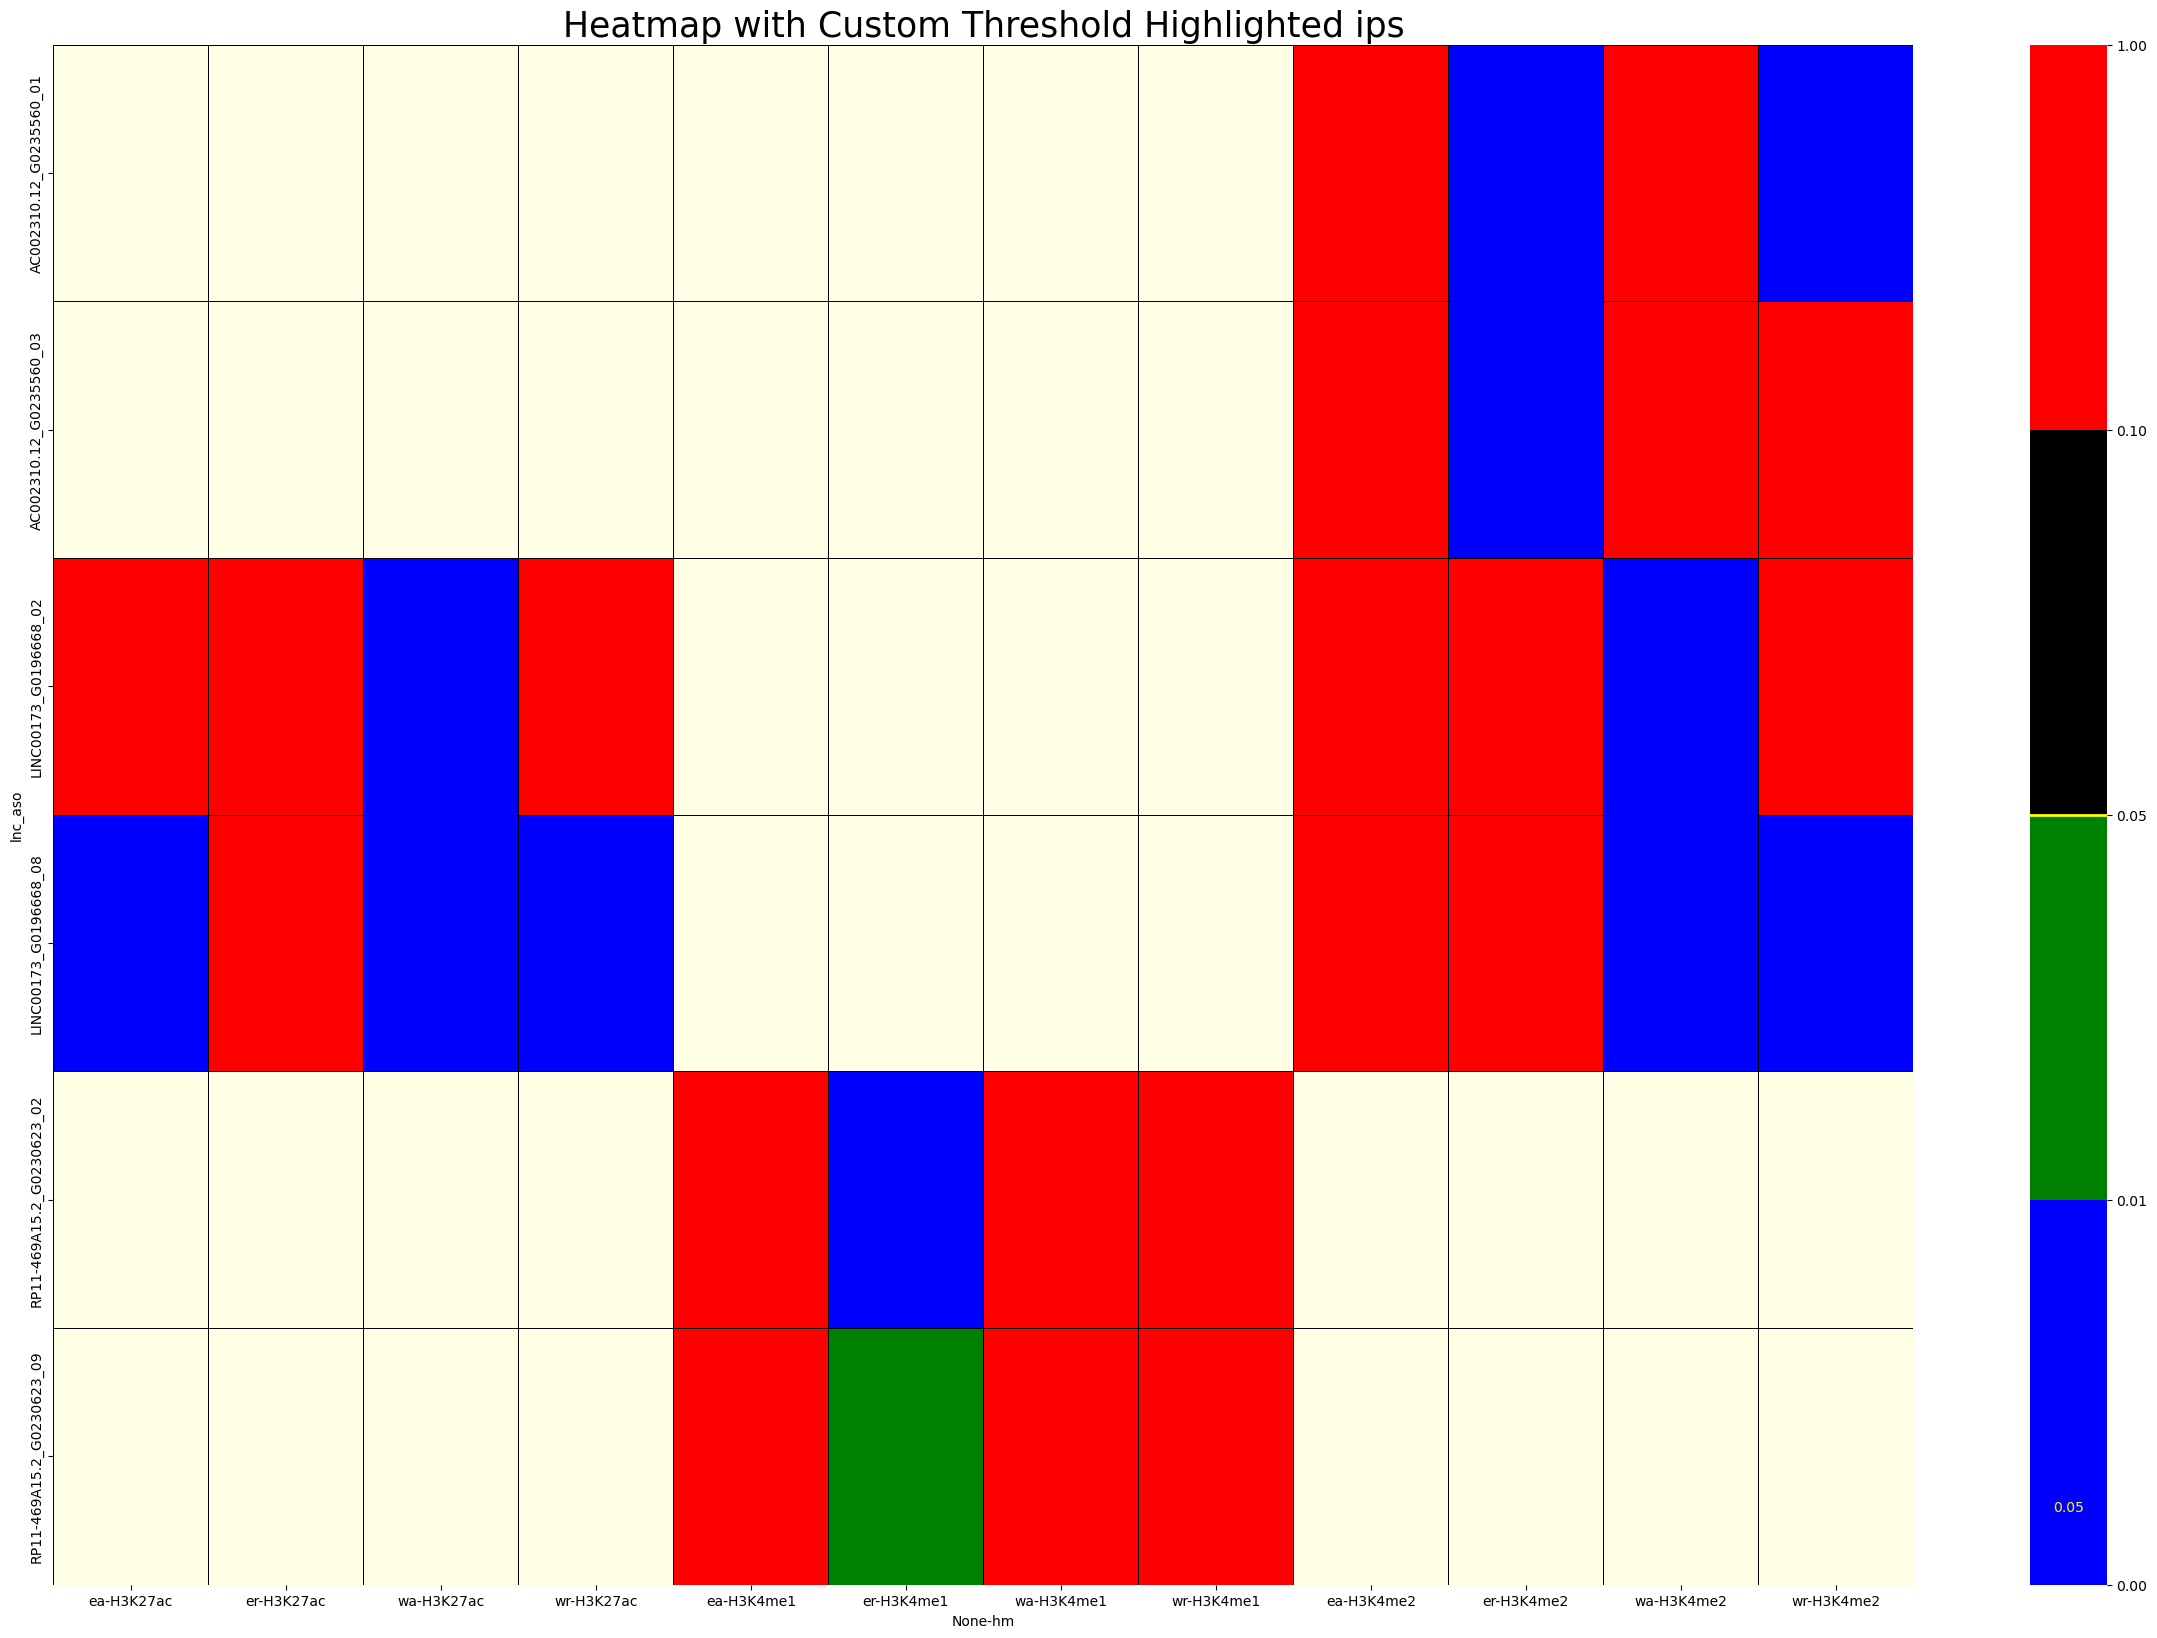

In [288]:
heatmap_pval_blue_red(df=fisher_results_filt_two_aso_by_exp["ips"], exp="ips")

## Сравнение результатов между тканями

In [290]:
set(fisher_results_filt_by_exp["ips"]["lnc-aso-hm"]) & set(fisher_results_filt_by_exp["fibro"]["lnc-aso-hm"])

{'SBF2-AS1-G0246273_02-H3K4me2'}

In [291]:
shared_pairs = set(fisher_results_filt_by_exp["ips"]["lnc-hm"]) & set(fisher_results_filt_by_exp["fibro"]["lnc-hm"])
shared_pairs

{'MAPKAPK5-AS1-H3K27me3',
 'MAPKAPK5-AS1-H3K4me1',
 'MAPKAPK5-AS1-H3K4me3',
 'RP3-510D11.2-H3K4me2',
 'SBF2-AS1-H3K4me2',
 'ZNF674-AS1-methylation'}

In [296]:
mask = fisher_results_filt_by_exp["ips"]["lnc-hm"].isin(shared_pairs)
ips_shared_pairs = fisher_results_filt_by_exp["ips"][mask].sort_values(by="lnc-hm")
ips_shared_pairs

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm,lnc_aso
25,H3K27me3,ENSG00000234608,G0234608_03,0.001612,1.000000,1.000000e+00,1.000000e+00,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,MAPKAPK5-AS1-G0234608_03-H3K27me3,MAPKAPK5-AS1_G0234608_03
38,H3K4me1,ENSG00000234608,G0234608_03,0.000368,1.000000,1.000000e+00,1.000000e+00,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me1,MAPKAPK5-AS1-G0234608_03-H3K4me1,MAPKAPK5-AS1_G0234608_03
1,H3K4me3,ENSG00000234608,G0234608_03,0.002363,1.000000,5.232568e-02,1.297265e-12,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_03-H3K4me3,MAPKAPK5-AS1_G0234608_03
2,H3K4me3,ENSG00000234608,G0234608_AD_08,1.000000,1.000000,1.086221e-08,1.000000e+00,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_AD_08-H3K4me3,MAPKAPK5-AS1_G0234608_AD_08
15,H3K4me2,ENSG00000234546,G0234546_02,0.005519,0.037358,1.000000e+00,1.039173e-01,RP3-510D11.2,RP3-510D11.2-H3K4me2,RP3-510D11.2-G0234546_02-H3K4me2,RP3-510D11.2_G0234546_02
18,H3K4me2,ENSG00000246273,G0246273_02,0.015846,0.722903,2.342931e-01,1.000000e+00,SBF2-AS1,SBF2-AS1-H3K4me2,SBF2-AS1-G0246273_02-H3K4me2,SBF2-AS1_G0246273_02
8,methylation,ENSG00000230844,G0230844_AD_07,1.000000,0.001146,7.588105e-01,7.732718e-01,ZNF674-AS1,ZNF674-AS1-methylation,ZNF674-AS1-G0230844_AD_07-methylation,ZNF674-AS1_G0230844_AD_07


In [297]:
mask = fisher_results_filt_by_exp["fibro"]["lnc-hm"].isin(shared_pairs)
fibro_shared_pairs = fisher_results_filt_by_exp["fibro"][mask].sort_values(by="lnc-hm")
fibro_shared_pairs

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm
23,H3K27me3,ENSG00000234608,G0234608_06,6.738423e-68,0.270785,2.930994e-04,0.701667,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,MAPKAPK5-AS1-G0234608_06-H3K27me3
24,H3K27me3,ENSG00000234608,G0234608_AD_01,3.623438e-02,1.000000,1.000000e+00,0.625915,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,MAPKAPK5-AS1-G0234608_AD_01-H3K27me3
25,H3K27me3,ENSG00000234608,G0234608_AD_04,4.346245e-12,1.000000,1.000000e+00,0.054599,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,MAPKAPK5-AS1-G0234608_AD_04-H3K27me3
263,H3K4me1,ENSG00000234608,G0234608_06,8.222331e-164,0.000324,5.920976e-10,0.008159,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me1,MAPKAPK5-AS1-G0234608_06-H3K4me1
264,H3K4me1,ENSG00000234608,G0234608_AD_01,2.810353e-08,0.061168,1.236386e-04,0.522675,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me1,MAPKAPK5-AS1-G0234608_AD_01-H3K4me1
265,H3K4me1,ENSG00000234608,G0234608_AD_04,7.690754e-03,0.020729,9.110438e-15,0.340191,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me1,MAPKAPK5-AS1-G0234608_AD_04-H3K4me1
217,H3K4me3,ENSG00000234608,G0234608_06,7.661167e-83,0.000011,1.908835e-34,0.000268,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_06-H3K4me3
218,H3K4me3,ENSG00000234608,G0234608_AD_01,8.981877e-02,0.018437,1.868384e-08,0.289247,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_AD_01-H3K4me3
219,H3K4me3,ENSG00000234608,G0234608_AD_04,1.932420e-02,0.111652,6.321523e-22,1.000000,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_AD_04-H3K4me3
138,H3K4me2,ENSG00000234546,G0234546_07,8.189066e-02,0.000809,1.000000e+00,1.000000,RP3-510D11.2,RP3-510D11.2-H3K4me2,RP3-510D11.2-G0234546_07-H3K4me2


<Axes: ylabel='lnc-aso-hm'>

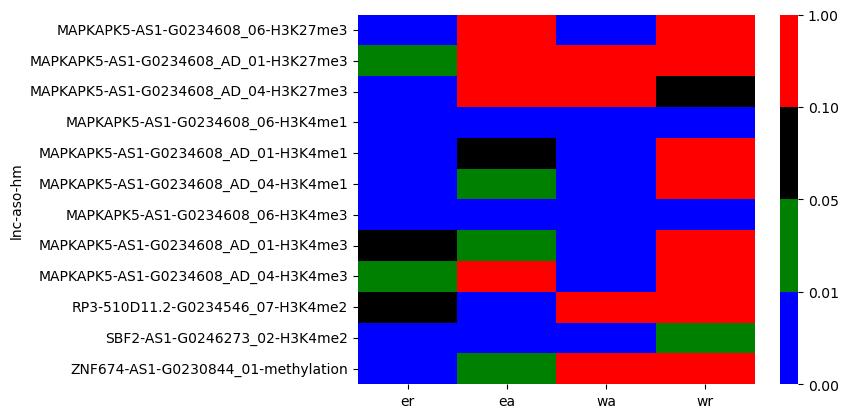

In [298]:
cmap = ListedColormap(['blue', 'green', 'black', 'red'])
bounds = [0, 0.01, 0.05, 0.1, 1]
norm = BoundaryNorm(bounds, cmap.N)
sns.heatmap(fibro_shared_pairs[["lnc-aso-hm", "er", "ea", "wa", "wr"]].set_index("lnc-aso-hm"), cmap=cmap, cbar_kws={'boundaries': bounds, 'ticks': [0, 0.01, 0.05, 0.1, 1]}, norm=norm)

<Axes: ylabel='lnc-aso-hm'>

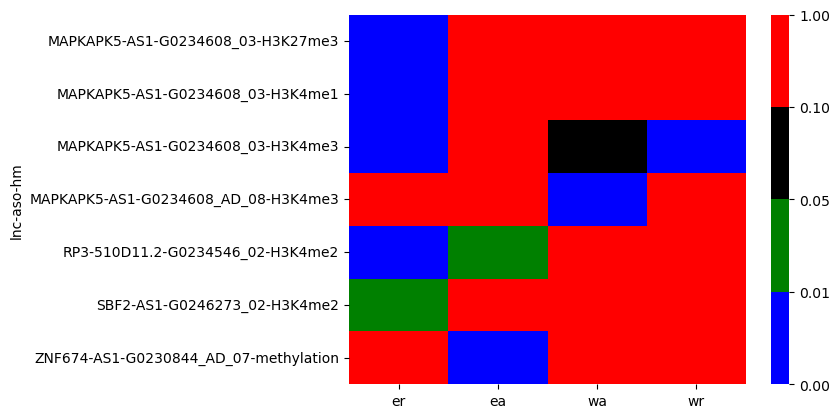

In [299]:
sns.heatmap(ips_shared_pairs[["lnc-aso-hm", "er", "ea", "wa", "wr"]].set_index("lnc-aso-hm"), cmap=cmap, cbar_kws={'boundaries': bounds, 'ticks': [0, 0.01, 0.05, 0.1, 1]}, norm=norm)